# The matrix product state Born machine

**Marcin Płodzień** — Institute of Theoretical Physics, Jagiellonian University in Kraków  
[ORCID 0000-0002-0835-1644](https://orcid.org/0000-0002-0835-1644) · [github.com/MarcinPlodzien](https://github.com/MarcinPlodzien) · [www](https://chaos.if.uj.edu.pl/marcinplodzien/)

*Quantum Many-Body Simulation — Chapter 13 — Quantum machine learning*

## 1. Introduction

The matrix product state (MPS) Born machine was introduced in [[1]](#ref-1). Below, the bars-and-stripes experiment of
[[1]](#ref-1) and its MNIST experiments, at a reduced scale, are repeated and compared with the published numbers.

### 1.1 Generative modelling: learning a distribution over bit strings

A *classifier* is a function that assigns a label to an image. A *generative model* learns
instead the probability distribution of the images themselves. Given a training set $\mathcal T$ of $N_{\rm T}$
examples, all drawn from an unknown distribution, it builds a model distribution $P(\mathbf v)$ that can

* assign a probability to any new example (and so tell a typical example from an atypical one),
* produce new examples by sampling, and
* fill in missing parts of an example by sampling them conditioned on the known parts.

We consider binary data: an example is a string $\mathbf v=(v_0,v_1,\dots,v_{N-1})$ of $N$ bits $v_j\in\{0,1\}$,
for instance a black-and-white image of $N$ pixels. Pixels, bits and sites of the chain are counted from 0.
A distribution over such strings is a table of $2^N$ non-negative numbers that add up to one. For a
$14\times14$ image, $N=196$ and $2^{196}\approx10^{59}$: the table cannot be stored, and a model must describe it with
far fewer parameters while keeping the three operations above cheap.

### 1.2 The Born rule as a model

Quantum mechanics has a ready-made answer. A state of $N$ qubits is a vector of $2^N$ amplitudes $\psi(\mathbf v)$,
one per basis state $\vert v_0v_1\cdots v_{N-1}\rangle$, and a measurement of all qubits in the computational basis
returns the string $\mathbf v$ with the probability $\vert\psi(\mathbf v)\vert^2$ (the Born rule [[2]](#ref-2)). Any
wave function therefore defines a probability distribution over bit strings, positive by construction. A *Born
machine* uses this as a model: it parametrises a wave function and trains it so that the measurement statistics of
the state reproduce the data. The state never needs a quantum computer; it is a classical data structure that is
evaluated, trained and sampled on a CPU. The wave function is stored as a matrix product state, the format
used for weakly entangled many-body states, which makes the normalisation, the sampling and the training
cheap (Sections 3–5).

Here the chain of tensors is a wave function, and an image is a basis state, the bit string itself. No label is involved: the training is
unsupervised.

### 1.3 Road map

* **Section 3** defines the model, computes the normalisation by a transfer-matrix contraction and by the canonical
  form, and checks both against the explicit $2^N$-component state.
* **Section 4** derives the negative log-likelihood, its relation to the Kullback–Leibler divergence, its gradient
  with respect to a two-site bond tensor (Eq. (5) of [[1]](#ref-1)), and the sweeping training with an adaptive SVD
  split; the gradient is checked against `jax.grad`.
* **Section 5** samples from the MPS exactly, also with some bits fixed, and tests the samplers against the exact
  distribution of a small chain.
* **Section 6** learns the bars-and-stripes data set of [[1]](#ref-1), Sec. III A, and explains the learned bond
  dimensions by the block structure of the data and the signs of the amplitudes.
* **Section 7** trains on binarised $14\times14$ MNIST digits: likelihood against bond dimension and training-set
  size, overfitting, the map of learned bond dimensions, generated digits and the reconstruction of missing pixels.
* **Section 8** trains the same model by automatic differentiation of the whole contraction with Adam, and compares.
* **Section 9** compares the entanglement of the learned states with that of the data; **Sections 10–11** give the
  cost and the limits of the method.

### What you will learn

*Physics*

* how the Born rule turns a many-body wave function into a probability distribution, and why the signs of the
  amplitudes, which change no probability, still change the entanglement;
* the number of disconnected blocks of a data set across a cut as a lower bound on the bond dimension of any model
  that reproduces the data exactly;
* why a model of limited bond dimension cannot represent the superposition of the MNIST training images and puts
  almost all of its probability on strings outside the training set.

*Numerical methods*

* maximum likelihood, the negative log-likelihood and its lower bound, the Kullback–Leibler divergence, an
  independent-pixel baseline and the standard error of a test-set mean;
* the gradient of the log-likelihood with respect to a bond tensor in mixed-canonical form, a line search on the unit
  sphere, the SVD split with a relative cutoff and a maximal bond dimension;
* exact sequential sampling and conditional sampling from an MPS, and statistical tests of a sampler (total variation
  distance with its sampling spread, likelihood-ratio test).

*Implementation practice*

* per-image environments rescaled to unit norm with a tracked logarithm, exact because the gradient is invariant
  under the rescaling;
* one compiled function for all bond updates of all sweeps (static padded shapes, a traced cap on the bond
  dimension), `lax.scan` and `vmap` in the samplers;
* validation of every piece against the explicit state of a short chain.

The notebook assumes matrix product states, their canonical forms and truncation, and the sweeps of two-site DMRG
([notebook 18, matrix product states](../ch07_tensor_networks/18_mps_tebd.ipynb)), the matrix product state classifier and its
training by sweeps and by automatic differentiation
([notebook 56, tensor networks for machine learning](56_tensor_networks_for_machine_learning.ipynb)), the sampling of
bit strings from a state vector ([notebook 08, measurements](../ch03_matrix_free_engine/08_measurements.ipynb)), the Adam
optimiser ([notebook 41, optimisers](41_optimizers.ipynb)), and `jit`, `vmap`, `grad` and `lax.scan`
([notebook 01, JAX from scratch](../ch01_computational_toolbox/01_jax_from_scratch.ipynb)).

## Configuration

Every notebook of this course starts with the same cell. Choose where to run (`DEVICE`) and the floating-point precision (`PRECISION`): `"double"` = `float64/complex128` (default, recommended for physics), `"single"` = `float32/complex64` (half the memory, faster on consumer GPUs, but watch the round-off). All code below derives its dtypes from `RDTYPE`/`CDTYPE` and its check tolerances from `TOL`, so nothing else needs to change.

In [1]:
# ==============================================================================
# CONFIGURATION  -- adapt to your hardware, then run the notebook top to bottom
# ==============================================================================
DEVICE    = "auto"     # "auto": use a GPU if JAX finds one, else CPU | "cpu" | "gpu"
PRECISION = "double"   # "double": float64/complex128 | "single": float32/complex64

import os
if DEVICE == "cpu":
    os.environ["JAX_PLATFORMS"] = "cpu"          # must be set BEFORE jax is imported

import string
from functools import partial

import math
import numpy as np
import jax
import jax.numpy as jnp
from jax import lax

# Precision is configurable: "double" = float64/complex128 (default; needed for long time evolutions and
# tight validation), "single" = float32/complex64 (half the memory, faster on consumer GPUs).
# In a notebook PRECISION is defined in the Configuration cell; for this module use the env var QE_PRECISION.
PRECISION = globals().get("PRECISION", os.environ.get("QE_PRECISION", "double"))
jax.config.update("jax_enable_x64", PRECISION == "double")
RDTYPE = jnp.float64 if PRECISION == "double" else jnp.float32       # real dtype
CDTYPE = jnp.complex128 if PRECISION == "double" else jnp.complex64  # complex dtype of all states/operators
TOL = 1e-10 if PRECISION == "double" else 1e-4                       # tolerance for sanity checks (asserts)
_LETTERS = string.ascii_letters  # the 52 einsum index labels a-z, A-Z

import time
import matplotlib.pyplot as plt

if DEVICE == "gpu" and jax.default_backend() == "cpu":
    print("WARNING: DEVICE='gpu' requested but JAX found no GPU -- running on CPU.")
print(f"JAX {jax.__version__} | backend: {jax.default_backend()} | devices: {jax.devices()}")
print(f"precision: {PRECISION} -> real {RDTYPE.__name__}, complex {CDTYPE.__name__}, check tolerance TOL={TOL:g}")


JAX 0.11.0 | backend: cpu | devices: [CpuDevice(id=0)]
precision: double -> real float64, complex complex128, check tolerance TOL=1e-10


## 2. Engine recap and notebook helpers

From the engine we take the Adam update, used in Section 8. The MPS Born machine, its training, the
samplers and the entanglement analysis are defined in this notebook. The helper cell sets the plot style and a timer
for the sections. The model is real-valued, so only `RDTYPE` of the configuration cell is used.

In [2]:
#| code-fold: true
#| code-summary: "Engine recap — the simulator primitives used in this notebook (click to expand)"
# ==============================================================================
# ENGINE RECAP: the functions of quantum_engine.py (SmoQ.jax) used in this notebook.
# Each one is derived, with its mathematics and an independent check, in notebook 08b
# (Chapter 3), 'Building the quantum simulator engine'.
# States are rank-N tensors of shape (2,)*N; every operator acts through ONE einsum.
# ==============================================================================
# ----------------------------------------------------------------------------
# 15. Variational circuits: ansatz, gradients, optimizers
# ----------------------------------------------------------------------------
def adam_init(theta):
    """Adam state: (first moment m, second moment v, step counter t)."""
    return (jnp.zeros_like(theta), jnp.zeros_like(theta), 0)

def adam_update(theta, g, state, lr=0.05, b1=0.9, b2=0.999, eps=1e-8):
    """One Adam step (Kingma & Ba):  m <- b1 m + (1-b1) g,  v <- b2 v + (1-b2) g^2,
        theta <- theta - lr * m_hat / (sqrt(v_hat) + eps),   hats = bias-corrected moments.
    Momentum (m) averages noisy gradients (great with SPSA); v gives a per-parameter step size."""
    m, v, t = state
    t = t + 1
    m = b1 * m + (1 - b1) * g
    v = b2 * v + (1 - b2) * g ** 2
    theta = theta - lr * (m / (1 - b1 ** t)) / (jnp.sqrt(v / (1 - b2 ** t)) + eps)
    return theta, (m, v, t)


In [3]:
# ==============================================================================
# PLOT STYLE + small helpers
# ==============================================================================
import itertools
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.stats import chi2 as chi2_dist

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]   # colour-blind-friendly, fixed order
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=PALETTE), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10, "legend.frameon": False})
SECTION_TIMES = {}                     # wall-clock seconds per section, printed in Section 10
_T0 = [time.perf_counter(), None]


def section_timer(name):
    """Close the timing of the previous section and open a new one called `name`."""
    now = time.perf_counter()
    if _T0[1] is not None:
        SECTION_TIMES[_T0[1]] = now - _T0[0]
    _T0[0], _T0[1] = now, name


def max_abs(a):
    """Largest absolute entry of an array, as a Python float."""
    return float(np.max(np.abs(np.asarray(a))))


def show_images(ax_row, imgs, side, titles=None, cmap="gray_r"):
    """Draw binary images (number, side*side) on a row of axes without ticks."""
    for k, ax in enumerate(ax_row):
        ax.imshow(np.asarray(imgs[k]).reshape(side, side), cmap=cmap, vmin=0, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        if titles is not None:
            ax.set_title(titles[k], fontsize=8)


def bit_codes(v):
    """Integer code of each bit string (rows of v), bit 0 most significant."""
    v = np.asarray(v)
    return v @ (2 ** np.arange(v.shape[1] - 1, -1, -1))


section_timer("3 model")

## 3. The model: a matrix product state over bits

### 3.1 Probabilities from a wave function

Following [[1]](#ref-1), Eq. (1), the model distribution is

$$P(\mathbf v)=\frac{\psi(\mathbf v)^2}{Z},\qquad Z=\sum_{\mathbf v\in\{0,1\}^N}\psi(\mathbf v)^2. \tag{1}$$

The amplitudes $\psi(\mathbf v)$ are real here, as in [[1]](#ref-1); $Z$ is called the *partition function* by
analogy with statistical physics. Dividing by $Z$ means that $\psi$ need not be normalised: any non-zero vector of
amplitudes defines a distribution, and multiplying $\psi$ by a constant changes nothing.

### 3.2 The wave function as a matrix product state

The amplitudes are stored as a matrix product state ([[1]](#ref-1), Eqs. (2)–(3)),

$$\psi(v_0,v_1,\dots,v_{N-1})=A^{[0]v_0}A^{[1]v_1}\cdots A^{[N-1]v_{N-1}}, \tag{2}$$

where $A^{[j]s}$ is a $\chi_j\times\chi_{j+1}$ matrix for each value $s\in\{0,1\}$ of bit $j$, and the boundary
dimensions are $\chi_0=\chi_N=1$, so the product is a number. *Bond* $j$, for $j=1,\dots,N-1$, is the cut between
sites $j-1$ and $j$, and $\chi_j$ is its bond dimension; this numbering is used throughout. The
bond dimensions limit the entanglement of the state ([notebook 18, matrix product states](../ch07_tensor_networks/18_mps_tebd.ipynb), Section 2.2): across bond $j$ the state has at most
$\chi_j$ Schmidt values and an entanglement entropy of at most $\ln\chi_j$. With all $\chi_j\leq\chi$, the state holds
at most $2N\chi^2$ numbers instead of $2^N$.

For JAX we use a zero-padded storage: one array `As` of shape $(N,\chi_{\rm s},2,\chi_{\rm s})$,
with `As[j][a, s, b]` $=A^{[j]s}_{ab}$ and zeros where a bond is smaller than the storage width $\chi_{\rm s}$. The
boundary bonds are index 0: only the row $a=0$ of the first tensor and the column $b=0$ of the last tensor are
non-zero. Every function then sees the same shapes, so each is compiled once. In code `As[j][:, v, :]` is the matrix
$A^{[j]v}$.

### 3.3 The normalisation by contraction

The sum (1) over $2^N$ strings factorises. Writing $\psi(\mathbf v)^2=\psi(\mathbf v)\psi(\mathbf v)$ with two copies
of the product (2) and summing every bit separately gives a product of *transfer matrices*: with
$E^{[0]}=1$ (a $1\times1$ matrix),

$$E^{[j+1]}_{bb'}=\sum_{s=0}^{1}\sum_{a,a'}E^{[j]}_{aa'}\,A^{[j]s}_{ab}\,A^{[j]s}_{a'b'},\qquad Z=E^{[N]}, \tag{3}$$

(einsum `"ab,asc,bsd->cd"`). Each step costs $O(\chi^3)$, the whole sum $O(N\chi^3)$ instead of $O(2^N)$. The
elements of $E^{[j]}$ can grow or shrink exponentially with $j$, so the code divides $E$ by its norm after every site
and adds the logarithm of that norm to $\ln Z$.

### 3.4 The canonical form makes $Z$ local

The gauge freedom of the MPS, the insertion of an invertible matrix and its inverse on a
bond, is used to make $Z$ even cheaper. A tensor is
*right-canonical* if $\sum_sA^{[j]s}(A^{[j]s})^{\rm T}=\mathbb 1$, *left-canonical* if
$\sum_s(A^{[j]s})^{\rm T}A^{[j]s}=\mathbb 1$ (here for real tensors). If every tensor
right of site $c$ is right-canonical, the transfer matrices summed from the right end are all identities, and if every
tensor left of $c$ is left-canonical, so are those from the left end. In this *mixed-canonical form* with the
*centre* $c$ ([[1]](#ref-1), Appendix A, Eq. (A2)), only the centre tensor remains:

$$Z=\sum_{s,a,b}\big(A^{[c]s}_{ab}\big)^2=\Vert A^{[c]}\Vert^2. \tag{4}$$

For the training of Section 4 the centre is a two-site tensor, and Eq. (4) holds with $A^{[c]}$ replaced by it.

### 3.5 From formula to code

The initial state of [[1]](#ref-1), Appendix B, has random tensors with all inner bond dimensions equal to 2, brought
into canonical form; with all $\chi_j=1$ the bond dimensions could hardly grow (endnote 68 of [[1]](#ref-1)). The cell
builds such a state in the padded format and makes it right-canonical with the centre on site 0 by a sweep of SVDs
from the right. This one-off sweep runs in NumPy: 195 small SVDs take milliseconds, while
compiling the sweep for every new shape would take seconds. The checkpoint compares Eq. (4) with the transfer-matrix
contraction (3) and with the explicit sum over all $2^{10}$ strings of a 10-site chain.

In [4]:
# ==============================================================================
# STEP 1: the MPS Born machine, its normalisation, and the canonical form
# ==============================================================================
@partial(jax.jit, static_argnames=("chi_out", "move_right"))
def svd_split(B, chi_out, cutoff, move_right, chi_cap=None):
    """Split a two-site tensor B[a, s, t, b] by an SVD of the matrix B[(a s), (t b)] (Eq. (10) below).

    MATH            B = U diag(lambda) V^T;  keep k with lambda_k > cutoff * lambda_0 and k < chi_cap (zero the rest)
                    move_right: A_j = U (left-canonical),  A_{j+1} = diag(lambda) V^T (new centre)
                    move left:  A_j = U diag(lambda) (new centre),  A_{j+1} = V^T (right-canonical)
                    the centre is divided by its norm, so Z = 1 afterwards, Eq. (4)
    ARGUMENTS       chi_out: storage width of the outputs (static); chi_cap: maximal bond dimension (traced, so one
                    compilation serves every cap), default chi_out
    RETURNS         A_j (chi_out, 2, chi_out), A_{j+1}, number of kept values, discarded weight
                    eps = sum_{dropped} lambda_k^2 / sum_k lambda_k^2
    """
    chi_cap = chi_out if chi_cap is None else chi_cap
    a, s, t, b = B.shape
    U, lam, Vt = jnp.linalg.svd(B.reshape(a * s, t * b), full_matrices=False)
    keep = (lam > cutoff * lam[0]) & (jnp.arange(lam.shape[0]) < chi_cap)
    lam_k = jnp.where(keep, lam, 0.0)
    eps = jnp.sum(jnp.where(keep, 0.0, lam ** 2)) / jnp.sum(lam ** 2)
    if move_right:
        A1 = (U[:, :chi_out] * keep[:chi_out]).reshape(a, s, chi_out)
        A2 = (lam_k[:chi_out, None] * Vt[:chi_out]).reshape(chi_out, t, b)
        A2 = A2 / jnp.linalg.norm(A2)
    else:
        A1 = (U[:, :chi_out] * lam_k[None, :chi_out]).reshape(a, s, chi_out)
        A1 = A1 / jnp.linalg.norm(A1)
        A2 = (Vt[:chi_out] * keep[:chi_out, None]).reshape(chi_out, t, b)
    return A1, A2, jnp.sum(keep), eps


def init_born_mps(seed, N, chi_s, chi_init=2):
    """Random MPS with inner bond dimensions chi_init, right-canonical, centre (normalised) on site 0.

    MATH            random Gaussian A^{[j]s} on a chi_init x chi_init block; boundary row / column 0 only;
                    sweep j = N-1 .. 1:  A_{j-1} A_j = (U lambda) V^T,  A_j <- V^T (right-canonical), A_{j-1} <- U lambda
    IMPLEMENTATION  NumPy on the host (fixed seed); returns a JAX array of shape (N, chi_s, 2, chi_s)
    """
    rng = np.random.default_rng(seed)
    blk = (np.arange(chi_s) < chi_init).astype(float)
    A = rng.standard_normal((N, chi_s, 2, chi_s)) * blk[None, :, None, None] * blk[None, None, None, :]
    A[0] *= (np.arange(chi_s) == 0)[:, None, None]                       # left boundary: row 0 only
    A[N - 1] *= (np.arange(chi_s) == 0)[None, None, :]                   # right boundary: column 0 only
    for j in range(N - 1, 0, -1):
        U, lam, Vt = np.linalg.svd(np.einsum("asm,mtb->astb", A[j - 1], A[j]).reshape(2 * chi_s, 2 * chi_s),
                                   full_matrices=False)
        keep = ((lam > 1e-14 * lam[0]) & (np.arange(lam.size) < chi_s))[:chi_s]
        A[j] = (Vt[:chi_s] * keep[:, None]).reshape(chi_s, 2, chi_s)
        C = (U[:, :chi_s] * (lam[:chi_s] * keep)[None, :]).reshape(chi_s, 2, chi_s)
        A[j - 1] = C / np.linalg.norm(C)
    return jnp.asarray(A, dtype=RDTYPE)


@jax.jit
def log_Z_transfer(As):
    """ln Z by the transfer matrices of Eq. (3), rescaled at every site.

    MATH            E <- sum_s A^{s T} E A^s  (einsum "ab,asc,bsd->cd"),  E / |E|,  lnZ += ln |E|;   Z = E[0, 0] at the end
    COST            O(N chi^3), valid for any MPS (canonical or not)
    """
    E = jnp.zeros((As.shape[1], As.shape[1]), RDTYPE).at[0, 0].set(1.0)

    def body(carry, A):
        E, lz = carry
        E = jnp.einsum("ab,asc,bsd->cd", E, A, A)
        nE = jnp.linalg.norm(E)
        return (E / nE, lz + jnp.log(nE)), None
    (E, lz), _ = lax.scan(body, (E, jnp.zeros((), RDTYPE)), As)
    return lz + jnp.log(E[0, 0])


def dense_state(As):
    """Contract the padded MPS into the explicit vector psi of length 2^N (NumPy; validation only, small N)."""
    As = np.asarray(As)
    T = As[0][0]                                                   # (2, chi): left boundary row 0
    for A in As[1:]:
        T = np.tensordot(T, A, axes=([-1], [0]))
    return T[..., 0].reshape(-1)                                   # right boundary column 0; bit 0 most significant


def trim_mps(As):
    """Drop the padding beyond the largest bond dimension in use (kept singular values are the first ones)."""
    used = np.any(np.asarray(As) != 0, axis=(0, 2))                  # (chi, chi): any non-zero entry A[:, a, :, b]
    k = int(max(np.nonzero(used.any(axis=1))[0].max(), np.nonzero(used.any(axis=0))[0].max())) + 1
    return As[:, :k, :, :k]


# CHECKPOINT: Z three ways on a 10-site chain, and the right-canonical condition
N_c, CHI_c = 10, 4
As_c = init_born_mps(0, N_c, CHI_c, chi_init=CHI_c)
psi_c = dense_state(As_c)
Z_dense = float(np.sum(psi_c ** 2))
Z_transfer = float(jnp.exp(log_Z_transfer(As_c)))
Z_centre = float(np.sum(np.asarray(As_c[0]) ** 2))
err_rc = max(max_abs(np.einsum("asb,csb->ac", A, A) - np.diag((np.abs(A).sum(axis=(1, 2)) > 0).astype(float)))
             for A in np.asarray(As_c[1:]))
print(f"N = {N_c}, chi = {CHI_c}:  Z (sum over 2^{N_c} strings) = {Z_dense:.15f}")
print(f"                 Z (transfer matrices, Eq. 3)  = {Z_transfer:.15f}")
print(f"                 Z (centre tensor, Eq. 4)      = {Z_centre:.15f}")
print(f"right-canonical condition, max |sum_s A^s A^sT - 1| over sites 1..{N_c - 1}: {err_rc:.1e}")
assert abs(Z_dense - Z_centre) < TOL and abs(Z_dense - Z_transfer) < TOL and err_rc < TOL

# a non-canonical MPS: the transfer matrices still give Z, the centre formula does not
As_nc = np.random.default_rng(1).standard_normal(As_c.shape) * (np.abs(np.asarray(As_c)) > 0)
Z_nc = float(np.sum(dense_state(As_nc) ** 2))
Z_nc_transfer = float(jnp.exp(log_Z_transfer(jnp.asarray(As_nc, dtype=RDTYPE))))
print(f"\nrandom (non-canonical) tensors: Z dense = {Z_nc:.6e},  transfer = {Z_nc_transfer:.6e},  "
      f"|A^[0]|^2 = {float(np.sum(As_nc[0] ** 2)):.6e}")
assert abs(Z_nc - Z_nc_transfer) < TOL * Z_nc

N = 10, chi = 4:  Z (sum over 2^10 strings) = 1.000000000000002
                 Z (transfer matrices, Eq. 3)  = 1.000000000000003
                 Z (centre tensor, Eq. 4)      = 1.000000000000000
right-canonical condition, max |sum_s A^s A^sT - 1| over sites 1..9: 1.1e-15

random (non-canonical) tensors: Z dense = 8.330282e+05,  transfer = 8.330282e+05,  |A^[0]|^2 = 1.813404e+00


The three values of $Z$ agree to round-off for the canonical state, and the right-canonical condition holds on
every site (on the padded entries it reads $0=0$, which is why the identity is masked to the non-zero rows). For
random tensors, which are not canonical, the transfer-matrix contraction still gives the right $Z$, while the norm of
one tensor is a different number: Eq. (4) holds only in the canonical form. The sweeps of
Section 4 keep the state in mixed-canonical form at every step, so $Z$ is always available for free.

In [5]:
section_timer("4 learning")

## 4. Learning from data

### 4.1 The negative log-likelihood and the Kullback–Leibler divergence

Maximum-likelihood learning chooses the parameters that make the observed data most probable. For independent
examples the probability of the whole training set is the product $\prod_{\mathbf v\in\mathcal T}P(\mathbf v)$; its
negative logarithm per example is the *negative log-likelihood* (NLL) of [[1]](#ref-1), Eq. (4),

$$\mathcal L=-\frac1{N_{\rm T}}\sum_{\mathbf v\in\mathcal T}\ln P(\mathbf v)
=\ln Z-\frac1{N_{\rm T}}\sum_{\mathbf v\in\mathcal T}\ln\psi(\mathbf v)^2, \tag{5}$$

measured in nats (natural logarithm). Let $\hat p(\mathbf v)=n(\mathbf v)/N_{\rm T}$ be the *empirical
distribution*, with $n(\mathbf v)$ the number of times $\mathbf v$ occurs in $\mathcal T$. Then
$\mathcal L=-\sum_{\mathbf v}\hat p(\mathbf v)\ln P(\mathbf v)$, and adding and subtracting
$\sum_{\mathbf v}\hat p\ln\hat p$,

$$\mathcal L=\underbrace{-\sum_{\mathbf v}\hat p(\mathbf v)\ln\hat p(\mathbf v)}_{H(\hat p)}
+\underbrace{\sum_{\mathbf v}\hat p(\mathbf v)\ln\frac{\hat p(\mathbf v)}{P(\mathbf v)}}_{D_{\rm KL}(\hat p\Vert P)}. \tag{6}$$

The second term is the Kullback–Leibler divergence [[3]](#ref-3) of the model from the empirical distribution. It is
non-negative and zero only for $P=\hat p$, so minimising $\mathcal L$ minimises $D_{\rm KL}$, as stated in
[[1]](#ref-1), Sec. II B. The first term, the Shannon entropy of the data, is the lower bound of $\mathcal L$. If all
$N_{\rm T}$ examples are different, $H(\hat p)=\ln N_{\rm T}$, and a model that reaches it has memorised the training
set: it gives probability $1/N_{\rm T}$ to every example and zero to everything else, including every image not in
the training set. Generalisation is measured instead by the NLL of a separate *test set*.

### 4.2 The bond tensor and the environments of the data

As in two-site DMRG ([notebook 18, matrix product states](../ch07_tensor_networks/18_mps_tebd.ipynb), Section 6), the training updates two
neighbouring tensors at a time. Merging sites $j$ and $j+1$ into the *bond tensor*
$B_{astb}=\sum_mA^{[j]s}_{am}A^{[j+1]t}_{mb}$ ([[1]](#ref-1), Eq. (B1); einsum `"asm,mtb->astb"`), the amplitude of a
training example is

$$\psi(\mathbf v)=\sum_{a,b}l_{\mathbf v,a}\,B_{a\,v_j\,v_{j+1}\,b}\,r_{\mathbf v,b},\qquad
\mathbf l_{\mathbf v}=A^{[0]v_0}\cdots A^{[j-1]v_{j-1}},\quad \mathbf r_{\mathbf v}=A^{[j+2]v_{j+2}}\cdots A^{[N-1]v_{N-1}}, \tag{7}$$

with $\mathbf l_{\mathbf v}$ a row and $\mathbf r_{\mathbf v}$ a column vector of length $\chi$: the *environments* of
example $\mathbf v$. A bit $v$ selects the matrix
$A^{[j]v}$, which is the contraction with the one-hot vector $(1-v,\,v)$. In mixed-canonical form with the centre on the bond, $Z=\Vert B\Vert^2$ by
Eq. (4).

### 4.3 The gradient

Both terms of Eq. (5) are differentiated with respect to $B$. In the first, $\partial\ln Z/\partial B=Z'/Z$ with
$Z'=\partial Z/\partial B$, and in mixed-canonical form $Z=\Vert B\Vert^2$ gives $Z'=2B$. In the second,
$\partial\ln\psi(\mathbf v)^2/\partial B=2\Psi'(\mathbf v)/\psi(\mathbf v)$, where by Eq. (7)
$\Psi'(\mathbf v)_{astb}=\partial\psi(\mathbf v)/\partial B_{astb}=l_{\mathbf v,a}\,\delta_{s,v_j}\,\delta_{t,v_{j+1}}\,r_{\mathbf v,b}$.
Together ([[1]](#ref-1), Eq. (5) and Eq. (B2)), the gradient $\Gamma=\partial\mathcal L/\partial B$ is

$$\Gamma_{astb}=\frac{2B_{astb}}{Z}
-\frac2{N_{\rm T}}\sum_{\mathbf v\in\mathcal T}\frac{l_{\mathbf v,a}\,\delta_{s,v_j}\,\delta_{t,v_{j+1}}\,r_{\mathbf v,b}}{\psi(\mathbf v)}. \tag{8}$$

The first term pushes probability away from every string, the second pulls it towards the training examples; they
are the two "phases" of the gradient of an energy-based model discussed in [[1]](#ref-1), Sec. II D 3, and here both
are exact. The data term is a sum over the examples of outer products $\mathbf l\otimes\mathbf r$, each added to the
block $(s,t)=(v_j,v_{j+1})$ selected by the two bits; the code groups the examples by these two bits, a one-hot
vector $\mathbf e_{\mathbf v}$ of length 4, and computes the sum as one matrix product (einsum `"npa,nb->pab"`).

### 4.4 Scale invariance and a step on the unit sphere

$\mathcal L$ does not change when $B$ is multiplied by a constant, because $Z$ and every $\psi(\mathbf v)^2$ scale
alike. Differentiating $\mathcal L(cB)=\mathcal L(B)$ with respect to $c$ at $c=1$ gives
$\sum B_{astb}\Gamma_{astb}=0$: the gradient $\Gamma$ is orthogonal to $B$. (Directly from Eq. (8): the first term
gives $2\Vert B\Vert^2/Z=2$, the second $\frac2{N_{\rm T}}\sum_{\mathbf v}\psi(\mathbf v)/\psi(\mathbf v)=2$.)

[[1]](#ref-1), Appendix B, updates $B$ by gradient descent with a learning rate, possibly several times per bond and
with adaptive learning rates. We keep the direction and choose the step by a line search that costs almost nothing.
Keep $\Vert B\Vert=1$ and let $\hat\Gamma=\Gamma/\Vert\Gamma\Vert$. Since $\hat\Gamma\perp B$, the tensors

$$B(\theta)=\cos\theta\,B-\sin\theta\,\hat\Gamma \tag{9}$$

form a great circle of unit norm, $Z(\theta)=1$, that leaves $B$ in the direction of steepest descent. The amplitudes
are linear in $B$: $\psi_\theta(\mathbf v)=\cos\theta\,\psi(\mathbf v)-\sin\theta\,\gamma(\mathbf v)$, where
$\gamma(\mathbf v)$ is Eq. (7) with $\hat\Gamma$ in place of $B$. After one evaluation of $\psi$ and $\gamma$ for all
examples, the cost along the circle, $-\frac1{N_{\rm T}}\sum_{\mathbf v}\ln\psi_\theta(\mathbf v)^2$ plus a constant, is
known for every $\theta$ at $O(N_{\rm T})$ operations. The code evaluates it on the grid
$\theta\in\{0\}\cup\{\frac\pi4 2^{-k}:k=0,\dots,25\}$ and takes the best point. The largest step, $\frac\pi4$, mixes $B$
and $\hat\Gamma$ with equal weights; the smallest, about $10^{-8}$, is far below any change that matters. Because
$\theta=0$ is on the grid, the step never increases the cost; only the truncation in the split that follows
(Section 4.5) can. There is no learning rate to tune.

### 4.5 The SVD split and adaptive bond dimensions

After the update the bond tensor is split by an SVD, as in DMRG ([[1]](#ref-1),
Eq. (B5)):

$$B_{(as),(tb)}=\sum_kU_{(as),k}\,\lambda_k\,V_{(tb),k},\qquad\text{keep }k\text{ with }\lambda_k>\varepsilon_{\rm cut}\lambda_0\text{ and }k<\chi_{\max}. \tag{10}$$

The relative cutoff $\varepsilon_{\rm cut}$ is that of [[1]](#ref-1), Appendix B; the maximal bond dimension
$\chi_{\max}$ is called $D_{\max}$ in [[1]](#ref-1), Sec. II D. The number of kept values sets the new bond dimension
$\chi_{j+1}$: it grows where the data are correlated across the bond and stays small where they are not, as
[[1]](#ref-1), Sec. II D 2, describes. Moving right, $A^{[j]}=U$ is left-canonical and $\mathrm{diag}(\lambda)V^{\rm T}$
is the new centre on site $j+1$; moving left, $A^{[j+1]}=V^{\rm T}$ is right-canonical and $U\mathrm{diag}(\lambda)$
is the new centre on site $j$. Either way the state stays in mixed-canonical form, and the new centre is divided by
its norm so that $Z=1$. Keeping the largest singular values is the best approximation of $B$ of that rank in the
Frobenius norm (the Eckart–Young theorem [[4]](#ref-4)), and the squared relative error is the discarded weight
$\varepsilon=\sum_{\rm dropped}\lambda_k^2/\sum_k\lambda_k^2$.

A *loop* of [[1]](#ref-1) is a sweep from one end of the chain to the other and back. [[1]](#ref-1) starts from the
right end; we start with the centre on site 0 and sweep to the right first, which is the same algorithm mirrored.

### 4.6 Environments per example, cached and rescaled

The environments are cached and advanced by one site per step: moving right,
$\mathbf l^{(j+1)}_{\mathbf v}=\mathbf l^{(j)}_{\mathbf v}A^{[j]v_j}$ (einsum `"na,ns,asb->nb"` with the one-hot
bits), and moving left $\mathbf r^{(j)}_{\mathbf v}=A^{[j]v_j}\mathbf r^{(j+1)}_{\mathbf v}$. Their norms shrink
exponentially along the chain: the whole amplitude is a product of such factors, and $\psi(\mathbf v)^2=P(\mathbf v)$
is $e^{-25}$ to $e^{-45}$ for a typical training image of Section 7 (an NLL of 25 to 45 nats), and
$2^{-196}\approx e^{-136}$ for a uniform distribution over 196 bits. Here the data term of Eq. (8) helps: each example
enters through $\mathbf l_{\mathbf v}\otimes\mathbf r_{\mathbf v}/\psi(\mathbf v)$, which does not change when
$\mathbf l_{\mathbf v}$ or $\mathbf r_{\mathbf v}$ is multiplied by any positive number. The code therefore divides
every environment by its own norm after every step and keeps the logarithm of the norm, which enters the value of
$\mathcal L$ and leaves its gradient unchanged.

### 4.7 From formula to code

The environments are stored as stacked arrays `Lst` of shape $(N,N_{\rm T},\chi_{\rm s})$ and `Rst` of shape
$(N+1,N_{\rm T},\chi_{\rm s})$, with their log-norms; `Lst[j]` contracts the sites left of $j$, `Rst[j]` the sites from
$j$ on. The function `bond_update` does everything at one bond: merge, line-search steps, split, new environment.
A whole loop is compiled into one function, `training_loop`, as two `lax.scan`s over the bond index whose carry holds
the tensors and one of the stacks, read and written with `.at[j].set(...)`. The cap
$\chi_{\max}$ is a traced argument, so models with different caps but the same storage width $\chi_{\rm s}$ and the
same $N_{\rm T}$ share one compilation. The checkpoints use a chain of $N=8$ sites with $\chi=4$:

1. the gradient (8), from the environments, against `jax.grad` of $\mathcal L$ computed from the explicit
   $2^8$-component state with $Z$ summed over all strings, for a bond tensor that is not normalised;
2. the orthogonality $\sum B_{astb}\Gamma_{astb}=0$ of Section 4.4;
3. the split (10) with nothing to discard reproduces $B$, and $U$ is left-canonical.

In [6]:
# ==============================================================================
# STEP 2: the pieces of a bond update, Eqs. (7)-(10)
# ==============================================================================
def onehot_sites(v):
    """bits v (M, N) -> one-hot (N, M, 2), site-major: onehot[j, m] = (1 - v_mj, v_mj)."""
    return jnp.swapaxes(jax.nn.one_hot(v, 2, dtype=RDTYPE), 0, 1)


@jax.jit
def env_step_left(L, A, oh):
    """l'[n, b] = sum_{a,s} l[n, a] oh[n, s] A[a, s, b], each row then divided by its norm.

    RETURNS  normalised l', ln |l'| per example (-inf where the amplitude is exactly zero)
    """
    L = jnp.einsum("na,ns,asb->nb", L, oh, A)
    nrm = jnp.linalg.norm(L, axis=1)
    return L / jnp.where(nrm > 0, nrm, 1.0)[:, None], jnp.log(nrm)


@jax.jit
def env_step_right(R, A, oh):
    """r'[n, a] = sum_{s,b} A[a, s, b] oh[n, s] r[n, b], each row then divided by its norm."""
    R = jnp.einsum("asb,ns,nb->na", A, oh, R)
    nrm = jnp.linalg.norm(R, axis=1)
    return R / jnp.where(nrm > 0, nrm, 1.0)[:, None], jnp.log(nrm)


def pair_onehot(oh_j, oh_k):
    """One-hot vector e_v of the bit pair (v_j, v_{j+1}), index p = 2 s + t:  (M, 4)."""
    return (oh_j[:, :, None] * oh_k[:, None, :]).reshape(-1, 4)


def bond_amplitudes(B, L, oh_j, oh_k, R):
    """Eq. (7): psi[n] = sum_{a,b} l[n, a] B[a, v_j, v_{j+1}, b] r[n, b]   (up to the stored log-norms)."""
    a, _, _, b = B.shape
    Bp = jnp.transpose(B.reshape(a, 4, b), (1, 0, 2))                  # (4, a, b): block p = (s, t)
    LB = jnp.einsum("na,pab->npb", L, Bp)
    return jnp.einsum("npb,np,nb->n", LB, pair_onehot(oh_j, oh_k), R)


def nll_gradient(B, L, oh_j, oh_k, R):
    """Eq. (8): Gamma = 2 B / Z - (2 / N_T) sum_n l_n (x) e_{v_j} (x) e_{v_j+1} (x) r_n / psi_n,  Z = |B|^2.

    IMPLEMENTATION  the data term is one matrix product: sum_n (e_n (x) l_n / psi_n) r_n^T, einsum "npa,nb->pab"
    """
    a, s, t, b = B.shape
    psi = bond_amplitudes(B, L, oh_j, oh_k, R)
    W = pair_onehot(oh_j, oh_k)[:, :, None] * (L / psi[:, None])[:, None, :]        # (N_T, 4, a)
    data = jnp.transpose(jnp.einsum("npa,nb->pab", W, R), (1, 0, 2)).reshape(a, s, t, b)
    return 2 * B / jnp.sum(B ** 2) - 2 * data / L.shape[0]


THETAS = jnp.concatenate([jnp.zeros(1, RDTYPE), (jnp.pi / 4) * 2.0 ** -jnp.arange(26.0, dtype=RDTYPE)])


def great_circle_step(B, L, oh_j, oh_k, R):
    """One step along Eq. (9), theta chosen on the grid THETAS by the exact local cost.

    MATH            B <- B/|B|;  Gamma_hat = Gamma/|Gamma|;  psi_theta = cos(theta) psi - sin(theta) gamma;
                    cost(theta) = -mean_n ln psi_theta[n]^2   (Z(theta) = 1);   theta* = argmin over the grid (0 included)
    """
    B = B / jnp.linalg.norm(B)
    psi = bond_amplitudes(B, L, oh_j, oh_k, R)
    Gam = nll_gradient(B, L, oh_j, oh_k, R)
    nG = jnp.linalg.norm(Gam)
    Gam_hat = Gam / jnp.where(nG > 0, nG, 1.0)          # Gamma = 0 exactly (bits that are 0 in every example): no step
    gam = bond_amplitudes(Gam_hat, L, oh_j, oh_k, R)
    cos_t, sin_t = jnp.cos(THETAS), jnp.sin(THETAS)
    cost = -jnp.mean(jnp.log((cos_t[:, None] * psi[None] - sin_t[:, None] * gam[None]) ** 2), axis=1)
    k = jnp.argmin(cost)
    return cos_t[k] * B - sin_t[k] * Gam_hat


def bond_update(A_j, A_k, L, lnL, R, lnR, oh_j, oh_k, chi_cap, cutoff, n_steps, move_right):
    """One bond of a sweep: merge (B = A_j A_{j+1}), n_steps line-search steps, split (10), new environment.

    RETURNS  A_j, A_{j+1}, new environment (l of site j+1 moving right, r of site j+1 moving left) and its log-norm,
             NLL of the training set after the split (Eq. (5), Z = 1), kept bond dimension, discarded weight
    """
    B = jnp.einsum("asm,mtb->astb", A_j, A_k)
    B, _ = lax.scan(lambda B, _: (great_circle_step(B, L, oh_j, oh_k, R), None), B, None, length=n_steps)
    A1, A2, kept, eps = svd_split(B, A_j.shape[0], cutoff, move_right, chi_cap)
    psi = bond_amplitudes(jnp.einsum("asm,mtb->astb", A1, A2), L, oh_j, oh_k, R)
    nll = -jnp.mean(2 * (jnp.log(jnp.abs(psi)) + lnL + lnR))
    if move_right:
        env, ln_env = env_step_left(L, A1, oh_j)
        ln_env = ln_env + lnL
    else:
        env, ln_env = env_step_right(R, A2, oh_k)
        ln_env = ln_env + lnR
    return A1, A2, env, ln_env, nll, kept, eps


# ------------------------------------------------------------------------------
# CHECKPOINTS on an N = 8 chain (setup in NumPy)
# ------------------------------------------------------------------------------
N_g, CHI_g, j_g = 8, 4, 3
As_g = np.array(init_born_mps(2, N_g, CHI_g, chi_init=CHI_g))
for j in range(j_g):                                     # move the centre to site j_g by exact SVD splits (NumPy)
    U, lam, Vt = np.linalg.svd(np.einsum("asm,mtb->astb", As_g[j], As_g[j + 1]).reshape(2 * CHI_g, -1),
                               full_matrices=False)
    As_g[j] = U[:, :CHI_g].reshape(CHI_g, 2, CHI_g)
    As_g[j + 1] = (lam[:CHI_g, None] * Vt[:CHI_g]).reshape(CHI_g, 2, CHI_g)
v_g = (np.random.default_rng(3).random((12, N_g)) < 0.4).astype(np.int32)      # 12 training strings
oh_g = np.asarray(onehot_sites(v_g))
L_g = np.zeros((12, CHI_g))
L_g[:, 0] = 1.0
for j in range(j_g):
    L_g = np.einsum("na,ns,asb->nb", L_g, oh_g[j], As_g[j])                  # unnormalised environments
R_g = np.zeros((12, CHI_g))
R_g[:, 0] = 1.0
for j in range(N_g - 1, j_g + 1, -1):
    R_g = np.einsum("asb,ns,nb->na", As_g[j], oh_g[j], R_g)
B_g = 1.7 * np.einsum("asm,mtb->astb", As_g[j_g], As_g[j_g + 1])        # bond tensor, |B|^2 = Z = 2.89


def nll_dense(B):
    """Eq. (5) from the explicit 2^N state with B inserted at sites j_g, j_g + 1; Z summed over all strings."""
    T = jnp.asarray(As_g[0][0])
    for j in range(1, N_g):
        if j == j_g:
            T = jnp.tensordot(T, B, axes=([-1], [0]))
        elif j != j_g + 1:
            T = jnp.tensordot(T, jnp.asarray(As_g[j]), axes=([-1], [0]))
    psi = T[..., 0].reshape(-1)
    idx = bit_codes(v_g)
    return jnp.log(jnp.sum(psi ** 2)) - jnp.mean(jnp.log(psi[idx] ** 2))


Gam_formula = np.asarray(jax.jit(nll_gradient)(B_g, L_g, oh_g[j_g], oh_g[j_g + 1], R_g))
Gam_autodiff = np.asarray(jax.jit(jax.grad(nll_dense))(jnp.asarray(B_g)))
err_G = max_abs(Gam_formula - Gam_autodiff) / max_abs(Gam_autodiff)
print(f"Eq. (8) against jax.grad of the explicit NLL: max |difference| / max |grad| = {err_G:.1e}")
print(f"sum B Gamma = {float(np.sum(B_g * Gam_formula)):.1e}   (|B| |Gamma| = "
      f"{float(np.linalg.norm(B_g) * np.linalg.norm(Gam_formula)):.2f})")
A1_g, A2_g, kept_g, eps_g = svd_split(jnp.asarray(B_g), 2 * CHI_g, 0.0, move_right=True)
err_split = max_abs(np.einsum("asm,mtb->astb", A1_g, A2_g) * np.linalg.norm(B_g) - B_g)
err_lc = max_abs(np.einsum("asb,asc->bc", A1_g, A1_g) - np.diag((np.arange(2 * CHI_g) < int(kept_g)).astype(float)))
print(f"split with nothing discarded: max |A_j A_j+1 |B| - B| = {err_split:.1e},  kept {int(kept_g)} values, "
      f"discarded weight {float(eps_g):.1e},  max |U^T U - 1| = {err_lc:.1e}")
assert err_G < 1e3 * TOL and abs(float(np.sum(B_g * Gam_formula))) < 1e3 * TOL and err_split < TOL and err_lc < TOL

Eq. (8) against jax.grad of the explicit NLL: max |difference| / max |grad| = 2.0e-15
sum B Gamma = 3.9e-16   (|B| |Gamma| = 18.10)


split with nothing discarded: max |A_j A_j+1 |B| - B| = 6.7e-16,  kept 8 values, discarded weight 0.0e+00,  max |U^T U - 1| = 8.9e-16


The gradient (8), assembled from the environments of 12 strings, agrees with automatic differentiation of the
NLL computed the expensive way, with $Z$ summed over all $2^8$ strings, for a bond tensor of norm $1.7$. The term
$2B/Z$ is therefore correct, and it is correct *because* the other tensors are canonical: for a non-canonical MPS
$Z'$ is not $2B$. The gradient is orthogonal to $B$ to round-off, as Section 4.4 requires. The split keeps 8 values,
the full rank $2\times4$ of the matrix $B_{(as),(tb)}$, reproduces $B$ and gives a left-canonical $U$.

The next cell assembles the training: the right environments of the initial state, then loops of a right sweep and
a left sweep. After each loop it records the NLL of the training set (reported by the last bond update, which is the
NLL of the whole model), the bond dimensions, the largest discarded weight of the left sweep, the wall-clock time
and, if a test set is given, the NLL of every test image from a separate contraction (`log_psi` with Eq. (3) for $Z$).

In [7]:
# ==============================================================================
# STEP 3: loops of two-site sweeps
# ==============================================================================
@jax.jit
def log_psi(As, v):
    """ln |psi(v)| for bit strings v (M, N), contracted from the left with per-example rescaling (O(N chi^2) each)."""
    oh = onehot_sites(v)
    L0 = jnp.zeros((v.shape[0], As.shape[1]), RDTYPE).at[:, 0].set(1.0)

    def body(carry, inp):
        L, lz = carry
        L, ln = env_step_left(L, *inp)
        return (L, lz + ln), None
    (L, lz), _ = lax.scan(body, (L0, jnp.zeros(v.shape[0], RDTYPE)), (As, oh))
    return lz + jnp.log(jnp.abs(L[:, 0]))


def nll_of(As, v):
    """Eq. (5) for the strings v, with Z from Eq. (3).

    RETURNS  mean NLL over the strings with P > 0, number of strings with P = 0, array of -ln P (finite entries)
    """
    lp = 2 * np.asarray(log_psi(As, v)) - float(log_Z_transfer(As))
    ok = np.isfinite(lp)
    return float(-lp[ok].mean()), int((~ok).sum()), -lp[ok]


@jax.jit
def initial_right_envs(As, oh):
    """r_j (environment of the sites >= j) and its log-norm for j = 1 .. N-1, by a reverse lax.scan."""
    e0 = jnp.zeros((oh.shape[1], As.shape[1]), RDTYPE).at[:, 0].set(1.0)

    def body(carry, inp):
        R, lnR = carry
        R, ln = env_step_right(R, *inp)
        return (R, lnR + ln), (R, lnR + ln)
    _, (Rs, lnRs) = lax.scan(body, (e0, jnp.zeros(oh.shape[1], RDTYPE)), (As[1:], oh[1:]), reverse=True)
    return Rs, lnRs


@partial(jax.jit, static_argnames=("n_steps",))
def training_loop(As, Lst, lnL, Rst, lnR, oh, chi_cap, cutoff, n_steps):
    """One loop: right sweep over bonds 1..N-1, then left sweep back (Section 4.5).

    STORAGE         As (N, chi_s, 2, chi_s);  Lst[j], lnL[j]: environment of the sites < j, (N, N_T, chi_s), (N, N_T);
                    Rst[j], lnR[j]: environment of the sites >= j, (N+1, N_T, chi_s), (N+1, N_T)
    JAX             each sweep is a lax.scan over the bond index; the stacks are carried and updated with .at[].set,
                    which XLA performs in place inside the compiled loop; chi_cap is traced
    RETURNS         updated arrays and, per bond of the left sweep: NLL after the update, kept dimension, discarded weight
    """
    N = As.shape[0]

    def right(carry, j):
        As, Lst, lnL = carry
        A1, A2, env, ln_env, *_ = bond_update(As[j], As[j + 1], Lst[j], lnL[j], Rst[j + 2], lnR[j + 2], oh[j],
                                              oh[j + 1], chi_cap, cutoff, n_steps, True)
        return (As.at[j].set(A1).at[j + 1].set(A2), Lst.at[j + 1].set(env), lnL.at[j + 1].set(ln_env)), None
    (As, Lst, lnL), _ = lax.scan(right, (As, Lst, lnL), jnp.arange(N - 1))

    def left(carry, j):
        As, Rst, lnR = carry
        A1, A2, env, ln_env, nll, kept, eps = bond_update(As[j], As[j + 1], Lst[j], lnL[j], Rst[j + 2], lnR[j + 2],
                                                          oh[j], oh[j + 1], chi_cap, cutoff, n_steps, False)
        return (As.at[j].set(A1).at[j + 1].set(A2), Rst.at[j + 1].set(env), lnR.at[j + 1].set(ln_env)), (nll, kept, eps)
    (As, Rst, lnR), out = lax.scan(left, (As, Rst, lnR), jnp.arange(N - 2, -1, -1))
    return As, Lst, lnL, Rst, lnR, out


def train_born_machine(v, chi_max, loops, chi_s=None, cutoff=1e-7, n_steps=1, seed=10, v_test=None, chi_init=2):
    """Loops of right + left sweeps on the training strings v (N_T, N), bond dimensions capped at chi_max.

    chi_s: storage width (default chi_max); runs with the same chi_s and N_T share one compilation.
    RETURNS  final MPS (right-canonical, centre on site 0), history (one dict per loop)
    """
    chi_s = chi_max if chi_s is None else chi_s
    N, n = v.shape[1], v.shape[0]
    oh = onehot_sites(v)
    As = init_born_mps(seed, N, chi_s, chi_init)
    e0 = jnp.zeros((1, n, chi_s), RDTYPE).at[:, :, 0].set(1.0)
    R_init, lnR_init = initial_right_envs(As, oh)                    # right environments of the initial state
    Rst = jnp.concatenate([jnp.zeros_like(e0), R_init, e0])
    lnR = jnp.concatenate([jnp.zeros((1, n), RDTYPE), lnR_init, jnp.zeros((1, n), RDTYPE)])
    Lst = jnp.zeros((N, n, chi_s), RDTYPE).at[0].set(e0[0])
    lnL = jnp.zeros((N, n), RDTYPE)
    hist = []
    for _ in range(loops):
        t0 = time.perf_counter()
        As, Lst, lnL, Rst, lnR, (nll, kept, eps) = training_loop(As, Lst, lnL, Rst, lnR, oh, chi_max, cutoff, n_steps)
        nll, kept, eps = jax.device_get((nll, kept, eps))
        h = dict(train=float(nll[-1]), dims=np.asarray(kept[::-1]),      # dims[k]: dimension of bond k + 1
                 eps=float(eps.max()), time=time.perf_counter() - t0)
        if v_test is not None:
            h["test"], h["test_zero"], h["test_each"] = nll_of(As, v_test)
        hist.append(h)
    return As, hist

In [8]:
section_timer("5 sampling")

## 5. Direct sampling

### 5.1 Pixel by pixel from the chain rule

A Born machine is sampled the way a quantum state is measured qubit by qubit ([notebook 08, measurements](../ch03_matrix_free_engine/08_measurements.ipynb), Section 10.1): by the chain
rule of probability,

$$P(v_0,\dots,v_{N-1})=P(v_0)\,P(v_1\vert v_0)\,P(v_2\vert v_0v_1)\cdots P(v_{N-1}\vert v_0\cdots v_{N-2}), \tag{11}$$

a string is drawn by drawing $v_0$ from its marginal, then $v_1$ from its distribution conditioned on $v_0$, and so on.
Each draw needs a marginal of the first $k+1$ bits, a sum over the $2^{N-k-1}$ values of the others. The
right-canonical form makes this sum trivial: summing $\psi^2$ over the bits right of site $k$ produces the transfer
matrices of Eq. (3) from the right end, which are identities for right-canonical tensors. With the centre on site 0
and $Z=1$,

$$P(v_0,\dots,v_k)=\big\Vert x^{(k)}\big\Vert^2,\qquad x^{(k)}=A^{[0]v_0}A^{[1]v_1}\cdots A^{[k]v_k}, \tag{12}$$

and the conditional probability of the next bit is a ratio of two such norms,

$$P(v_{k+1}=s\vert v_0\cdots v_k)=\frac{\Vert x^{(k)}A^{[k+1]s}\Vert^2}{\Vert x^{(k)}\Vert^2}. \tag{13}$$

The vector $x^{(k)}$ is carried along and multiplied by one matrix per site, so a sample costs $O(N\chi^2)$, and every
sample is independent of the others: there is no Markov chain, no equilibration and no autocorrelation. This is
[[1]](#ref-1), Sec. II C, Eqs. (6)–(9), there written from the right end with left-canonical tensors. Measuring the
sites of an MPS one after the other with these probabilities, within one half-sweep, was introduced in
[[5]](#ref-5); its extension to other tensor networks is described in [[6]](#ref-6). For a state vector the same
procedure costs $O(2^N)$ per sample.

### 5.2 Conditional sampling with fixed bits

To reconstruct missing pixels, some bits are known and the others are sampled from their distribution conditioned on
the known ones ([[1]](#ref-1), Sec. II C, last paragraph). If the known bits are all at the start of the chain, Eq. (13)
applies unchanged: the known bits are inserted into $x^{(k)}$. If known bits also lie to the right of the current
site, the sum over the bits to the right is no longer an identity. It is the transfer matrix of Eq. (3) restricted to
the allowed values, computed from the right end for each example,

$$F^{[k]}=\sum_{s\in\mathcal S_k}A^{[k]s}F^{[k+1]}\big(A^{[k]s}\big)^{\rm T},\qquad F^{[N]}=1, \tag{14}$$

with $\mathcal S_k=\{0,1\}$ for a free bit and $\mathcal S_k=\{v_k\}$ for a known one. The conditional probability of
a free bit is then $P(v_{k+1}=s\vert\dots)\propto x^{(k)}A^{[k+1]s}F^{[k+2]}(x^{(k)}A^{[k+1]s})^{\rm T}$. In the code
the site being drawn is called $k$, so its environment is $F^{[k+1]}$, stored as `Fs[k]`. This is the ladder
contraction mentioned in [[1]](#ref-1), Sec. II C; it costs $O(N\chi^3)$ per example ([[1]](#ref-1), Sec. II D), and
it works for any pattern of known bits. Without known bits, $F^{[k]}$ is the identity on the occupied bond directions
of a right-canonical MPS and the formula reduces to Eq. (13).

### 5.3 From formula to code

`sample_born` implements Eq. (13) for many samples at once: a `lax.scan` over the sites carries the matrix of row
vectors $x$ of all samples, with one uniform random number per sample and site (passed in as an array); the bit is 1
if the random number is below $P(v_{k+1}=1\vert\dots)$. `sample_conditional` implements Eq. (14) for one example and is
`vmap`ped over examples. The checkpoints compare both with the exact distribution of a 10-site chain. With $M_{\rm s}$
samples and $m(\mathbf v)$ the number of times the sample $\mathbf v$ occurs,

* the *total variation distance* $\mathrm{TV}=\frac12\sum_{\mathbf v}\vert m(\mathbf v)/M_{\rm s}-P(\mathbf v)\vert$
  is never zero, because of the sampling noise. Its spread is obtained by drawing 200 sets of $M_{\rm s}$ samples from
  $P$ with NumPy's multinomial generator, which knows nothing about MPS; the MPS sampler passes if its TV lies within
  this spread;
* the likelihood-ratio statistic
  $G=2\sum_{\mathbf v}m(\mathbf v)\ln\frac{m(\mathbf v)}{M_{\rm s}P(\mathbf v)}=2M_{\rm s}D_{\rm KL}(m/M_{\rm s}\Vert P)$
  is, for a correct sampler and many samples per outcome, distributed approximately as the chi-squared distribution
  with (number of outcomes $-1$) degrees of freedom [[7]](#ref-7), whose mean is that number. This is the test used in
  [[1]](#ref-1), Sec. III A. The law is asymptotic: it needs a large expected count $M_{\rm s}P(\mathbf v)$ in every
  outcome. Outcomes with fewer than 5 expected counts are therefore merged into one bin before the test, and the
  cell prints how many were merged. The TV test with its exact multinomial reference has no such condition and is
  the primary test.

In [9]:
# ==============================================================================
# STEP 4: exact sampling (Eq. 13) and conditional sampling (Eq. 14)
# ==============================================================================
@jax.jit
def sample_born(u, As):
    """Independent samples of P(v) = psi(v)^2 for a right-canonical MPS with its centre on site 0, Eq. (13).

    u (N, n_samples): uniform random numbers, one per site and sample.  RETURNS bits (n_samples, N)
    JAX             lax.scan over the sites; carry x (n_samples, chi), renormalised per sample
    COST            O(N chi^2) per sample
    """
    x0 = jnp.zeros((u.shape[1], As.shape[1]), RDTYPE).at[:, 0].set(1.0)

    def body(x, inp):
        A, u_k = inp
        y = jnp.einsum("na,asb->nsb", x, A)                        # x A^s for s = 0, 1
        w = jnp.sum(y ** 2, axis=2)                                # |x A^s|^2
        bit = (u_k < w[:, 1] / (w[:, 0] + w[:, 1])).astype(jnp.int32)
        x = jnp.take_along_axis(y, bit[:, None, None], axis=1)[:, 0]
        return x / jnp.linalg.norm(x, axis=1, keepdims=True), bit
    _, bits = lax.scan(body, x0, (As, u))
    return bits.T


def draw(seed, As, n_samples):
    """n_samples exact samples from As (padding trimmed first) with a fixed seed."""
    u = jnp.asarray(np.random.default_rng(seed).random((As.shape[0], n_samples)), dtype=RDTYPE)
    return np.asarray(sample_born(u, trim_mps(As)))


def sample_conditional(key, As, v_given, known):
    """One sample of the free bits given the known bits (Eq. (14)), for any MPS.

    v_given (N,) bits (used where known), known (N,) bool.  RETURNS a full string (N,).
    MATH            F_k = sum_{s allowed} A_k^s F_{k+1} A_k^sT  (from the right, normalised);
                    p(s) ~ allowed(s) * (x A^s) F_{k+1} (x A^s)^T  for the site k being drawn;
                    known bits are inserted, free bits drawn
    COST            O(N chi^3)
    """
    N, chi = As.shape[0], As.shape[1]
    allowed = jnp.where(known[:, None], jax.nn.one_hot(v_given, 2, dtype=RDTYPE), 1.0)       # (N, 2)

    def env(F, inp):
        A, al = inp
        F = jnp.einsum("asb,s,bc,dsc->ad", A, al, F, A)
        return F / jnp.trace(F), F
    F_end = jnp.zeros((chi, chi), RDTYPE).at[0, 0].set(1.0)
    _, Fs = lax.scan(env, F_end, (As[1:], allowed[1:]), reverse=True)            # Fs[k] = F^{[k+1]}, k = 0..N-2
    Fs = jnp.concatenate([Fs, F_end[None]])                                      # F^{[k+1]} for k = 0..N-1
    u = jax.random.uniform(key, (N,), RDTYPE)

    def body(x, inp):
        A, F, al, u_k = inp
        y = jnp.einsum("a,asb->sb", x, A)
        w = al * jnp.einsum("sb,bc,sc->s", y, F, y)
        bit = (u_k < w[1] / (w[0] + w[1])).astype(jnp.int32)
        bit = jnp.where(al[0] == 0, 1, jnp.where(al[1] == 0, 0, bit))          # a known bit is inserted
        x = y[bit]
        return x / jnp.linalg.norm(x), bit
    x0 = jnp.zeros(chi, RDTYPE).at[0].set(1.0)
    _, bits = lax.scan(body, x0, (As, Fs, allowed, u))
    return bits


sample_conditional_batch = jax.jit(jax.vmap(sample_conditional, in_axes=(0, None, 0, None)))


def tv_distance(counts, p):
    return 0.5 * np.sum(np.abs(counts / counts.sum() - p))


def g_statistic(counts, p):
    """G = 2 sum m ln(m / (M_s p)) over the outcomes with m > 0."""
    m = counts > 0
    return 2 * np.sum(counts[m] * np.log(counts[m] / (counts.sum() * p[m])))


def g_test_merged(counts, p, min_expected=5.0):
    """G test after merging all outcomes with expected count M_s p < min_expected into one bin.

    RETURNS  G, degrees of freedom (bins - 1), p-value from the chi-squared distribution, number of merged outcomes
    """
    big = counts.sum() * p >= min_expected
    c = np.append(counts[big], counts[~big].sum())
    q = np.append(p[big], p[~big].sum())
    keep = q > 0
    G = g_statistic(c[keep], q[keep])
    dof = int(keep.sum()) - 1
    return G, dof, float(chi2_dist.sf(G, dof)), int((~big & (p > 0)).sum())


# CHECKPOINT 1: unconditional sampler against the exact distribution of the 10-site chain of Section 3
P_c = psi_c ** 2 / np.sum(psi_c ** 2)
M_S = 200_000
counts_c = np.bincount(bit_codes(draw(4, As_c, M_S)), minlength=2 ** N_c)
rng = np.random.default_rng(5)
tv_ref = np.array([tv_distance(rng.multinomial(M_S, P_c), P_c) for _ in range(200)])
tv_mps = tv_distance(counts_c, P_c)
G_c, dof_c, pval_c, merged_c = g_test_merged(counts_c, P_c)
print(f"unconditional, {M_S} samples, {2 ** N_c} outcomes: TV = {tv_mps:.5f};  TV of exact multinomial draws "
      f"{tv_ref.mean():.5f} +- {tv_ref.std():.5f}")
print(f"   G = {G_c:.1f} with {dof_c} degrees of freedom, p-value {pval_c:.3f}  ({merged_c} outcomes with expected "
      f"count below 5 merged into one bin)")
assert abs(tv_mps - tv_ref.mean()) < 4 * tv_ref.std()

# CHECKPOINT 2: conditional sampler, bits 2, 5 and 9 fixed to (1, 0, 1)
known_c = np.zeros(N_c, bool)
known_c[[2, 5, 9]] = True
v_fix = np.zeros(N_c, np.int32)
v_fix[[2, 5, 9]] = [1, 0, 1]
all_bits = (np.arange(2 ** N_c)[:, None] >> np.arange(N_c - 1, -1, -1)) & 1
consistent = np.all(all_bits[:, known_c] == v_fix[known_c], axis=1)
P_cond = np.where(consistent, P_c, 0.0) / np.sum(P_c[consistent])
M_C = 50_000
bits_cc = np.asarray(sample_conditional_batch(jax.random.split(jax.random.PRNGKey(6), M_C), As_c,
                                              jnp.tile(jnp.asarray(v_fix), (M_C, 1)), jnp.asarray(known_c)))
counts_cc = np.bincount(bit_codes(bits_cc), minlength=2 ** N_c)
tv_ref_c = np.array([tv_distance(rng.multinomial(M_C, P_cond), P_cond) for _ in range(200)])
tv_cond = tv_distance(counts_cc, P_cond)
G_cc, dof_cc, pval_cc, merged_cc = g_test_merged(counts_cc, P_cond)
print(f"conditional, {M_C} samples of the 7 free bits: known bits respected in all samples: "
      f"{bool(np.all(bits_cc[:, known_c] == v_fix[known_c]))};  TV = {tv_cond:.5f};  exact multinomial "
      f"{tv_ref_c.mean():.5f} +- {tv_ref_c.std():.5f};  G = {G_cc:.1f}, {dof_cc} dof, p-value {pval_cc:.3f}  "
      f"({merged_cc} outcomes merged)")
assert np.all(bits_cc[:, known_c] == v_fix[known_c]) and abs(tv_cond - tv_ref_c.mean()) < 4 * tv_ref_c.std()

unconditional, 200000 samples, 1024 outcomes: TV = 0.01343;  TV of exact multinomial draws 0.01376 +- 0.00066
   G = 442.6 with 466 degrees of freedom, p-value 0.776  (558 outcomes with expected count below 5 merged into one bin)


conditional, 50000 samples of the 7 free bits: known bits respected in all samples: True;  TV = 0.01322;  exact multinomial 0.01154 +- 0.00135;  G = 98.3, 91 dof, p-value 0.283  (37 outcomes merged)


Both samplers pass. The total variation distance of the MPS samples from the exact distribution is the size that
sampling noise alone produces for the same number of samples, and the likelihood-ratio statistic $G$ is close to its
number of degrees of freedom, with a p-value far from zero, once the outcomes with small expected counts are merged.
The conditional sampler never changes a known bit and reproduces the exact
conditional distribution of the seven free bits. A sampler with a wrong conditional probability, for instance one that
forgets the environment $F$ of Eq. (14), would fail the second test by many standard deviations (Exercise 3).

In [10]:
section_timer("6 bars and stripes")

## 6. Bars and stripes

### 6.1 The data, their blocks and their Schmidt ranks

The bars-and-stripes data set used in [[1]](#ref-1), Sec. III A, consists of the $4\times4$ binary images that have
only vertical bars or only horizontal stripes: $2^4$ images of each kind, of which two (all white, all black) are
both, so $30$ different images out of $2^{16}$. Each has probability $\frac1{30}$, and the lower bound of the NLL is
$H(\hat p)=\ln30=3.4012$. As in [[1]](#ref-1), Fig. 1(b), the pixels are put on the chain row by row, so bonds 4, 8
and 12 separate image rows.

A model that learns the data exactly has $\psi(\mathbf v)=\sigma(\mathbf v)/\sqrt{30}$ on the 30 images, with signs
$\sigma(\mathbf v)=\pm1$, and zero elsewhere. With all signs positive this is the uniform superposition

$$\vert\psi_{\rm BS}\rangle=\frac1{\sqrt{30}}\sum_{\mathbf v\in\mathcal T}\vert\mathbf v\rangle. \tag{15}$$

An exact MPS with given signs needs at each bond the Schmidt rank of its state across that cut. The Schmidt values of
a superposition of basis states can be found without the $2^N$ vector. Write each image as (prefix, suffix) at the
cut; the coefficient matrix $C_{\rm prefix,suffix}=\sigma(\mathbf v)\sqrt{\hat p(\mathbf v)}$ has one non-zero entry
per image, and its singular values are the Schmidt values. Prefixes and suffixes that share images form connected
*blocks* of $C$; different blocks use different rows and columns, so the SVD is done block by block, and a block that
holds a single image contributes the single value $\sqrt{\hat p}$. Every block holds at least one non-zero entry, so
the rank of $C$ is at least the number of blocks, *whatever the signs*. The number of blocks is therefore a lower
bound on the bond dimension of any exact model. Signs can raise the rank above it, and for other data sets a sign
choice can also lower the rank below that of the uniform superposition, but never below the number of blocks.

The function `data_state_profile` computes, for any data set and every cut, the Schmidt values of the state with
positive signs, Eq. (15), and the number of blocks; for bars and stripes it is checked against the dense SVD of the
$2^{16}$-component vector (15).

bars and stripes: 30 different 4x4 images; lower bound of the NLL ln 30 = 3.4012


Schmidt ranks of Eq. (15), bonds 1..15:       [2, 4, 8, 15, 16, 16, 16, 15, 16, 16, 16, 15, 8, 4, 2]
number of blocks (bound for any signs):       [2, 4, 8, 15, 16, 16, 16, 15, 16, 16, 16, 15, 8, 4, 2]
max |lambda^2 (dense SVD) - lambda^2 (blocks)| over all bonds = 2.2e-16
bond dimensions of the trained MPS in [1], Fig. 1(b): [2, 4, 8, 15, 16, 16, 16, 15, 16, 16, 16, 15, 8, 4, 2]


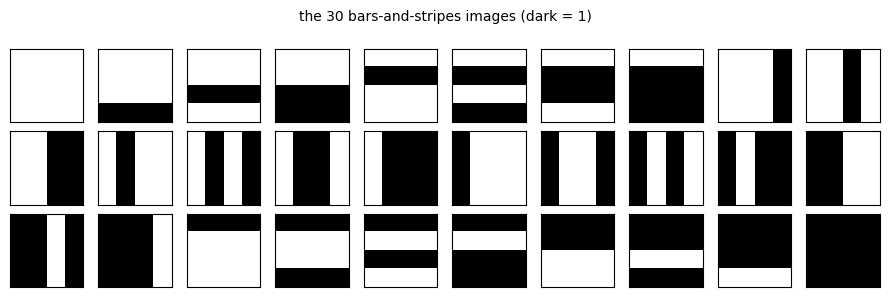

In [11]:
# ==============================================================================
# STEP 5: bars and stripes; Schmidt values and blocks of the data state, Eq. (15)
# ==============================================================================
def data_state_profile(v):
    """Squared Schmidt values (descending) of sum_v sqrt(p_hat(v)) |v> across every bond 1..N-1, and block counts.

    IMPLEMENTATION  distinct strings with weights p_hat; integer ids of all prefixes and suffixes, built site by site
                    (id_{k+1} = unique(2 id_k + v_k)); connected blocks of the bipartite prefix-suffix graph by scipy;
                    SVD per block (a block holding a single string contributes the value sqrt(p_hat))
    RETURNS         list of N-1 arrays of squared Schmidt values, array of N-1 block counts (bond k at index k-1)
    """
    uniq, cnt = np.unique(np.asarray(v, dtype=np.int64), axis=0, return_counts=True)
    amp = np.sqrt(cnt / cnt.sum())
    n_dist, N = uniq.shape
    pre = [np.zeros(n_dist, np.int64)]
    for k in range(N):
        pre.append(np.unique(2 * pre[-1] + uniq[:, k], return_inverse=True)[1].ravel())
    suf = [np.zeros(n_dist, np.int64)]
    for k in range(N - 1, -1, -1):
        suf.append(np.unique(2 * suf[-1] + uniq[:, k], return_inverse=True)[1].ravel())
    suf = suf[::-1]                                                 # suf[k]: id of the bits k .. N-1
    out, n_blocks = [], []
    for cut in range(1, N):
        p, q = pre[cut], suf[cut]
        n_p = p.max() + 1
        graph = coo_matrix((np.ones(n_dist), (p, n_p + q)), shape=(n_p + q.max() + 1,) * 2)
        _, comp = connected_components(graph, directed=False)
        ec = comp[p]
        sizes = np.bincount(ec)
        n_blocks.append(int(np.sum(sizes > 0)))
        values = [amp[sizes[ec] == 1]]
        for c in np.nonzero(sizes > 1)[0]:
            e = ec == c
            r, rinv = np.unique(p[e], return_inverse=True)
            t, tinv = np.unique(q[e], return_inverse=True)
            Cb = np.zeros((len(r), len(t)))
            Cb[rinv.ravel(), tinv.ravel()] = amp[e]
            values.append(np.linalg.svd(Cb, compute_uv=False))
        s2 = np.concatenate(values) ** 2
        out.append(np.sort(s2[s2 > 1e-24])[::-1])
    return out, np.array(n_blocks)


def entropy_nats(w):
    w = np.asarray(w)
    w = w[w > 1e-300]
    return float(-np.sum(w * np.log(w)))


BS_SIDE = 4
bs_set = set()
for rows in itertools.product([0, 1], repeat=BS_SIDE):
    img = np.repeat(np.array(rows)[:, None], BS_SIDE, axis=1)          # horizontal stripes
    bs_set.add(tuple(img.ravel()))
    bs_set.add(tuple(img.T.ravel()))                                   # vertical bars
V_BS = np.array(sorted(bs_set), dtype=np.int32)
N_BS = V_BS.shape[1]
print(f"bars and stripes: {len(V_BS)} different {BS_SIDE}x{BS_SIDE} images; lower bound of the NLL ln 30 = {np.log(30):.4f}")

# CHECKPOINT: Schmidt values of Eq. (15) by blocks against the dense SVD of the 2^16 vector
psi_bs = np.zeros(2 ** N_BS)
psi_bs[bit_codes(V_BS)] = 1 / np.sqrt(len(V_BS))
prof_data_bs, BLOCKS_BS = data_state_profile(V_BS)
RANK_BS, S_BS, err_bs = [], [], 0.0
for cut in range(1, N_BS):
    sv = np.linalg.svd(psi_bs.reshape(2 ** cut, -1), compute_uv=False)
    w_dense = sv[sv > 1e-12] ** 2
    w_block = prof_data_bs[cut - 1]
    err_bs = max(err_bs, np.max(np.abs(w_dense - w_block)) if len(w_dense) == len(w_block) else np.inf)
    RANK_BS.append(len(w_block))
    S_BS.append(entropy_nats(w_block))
print("Schmidt ranks of Eq. (15), bonds 1..15:      ", RANK_BS)
print("number of blocks (bound for any signs):      ", BLOCKS_BS.tolist())
print(f"max |lambda^2 (dense SVD) - lambda^2 (blocks)| over all bonds = {err_bs:.1e}")
print("bond dimensions of the trained MPS in [1], Fig. 1(b): [2, 4, 8, 15, 16, 16, 16, 15, 16, 16, 16, 15, 8, 4, 2]")
assert err_bs < TOL and RANK_BS == BLOCKS_BS.tolist()

fig, axes = plt.subplots(3, 10, figsize=(9, 3.0))
show_images(axes.flat, V_BS, BS_SIDE)
fig.suptitle("the 30 bars-and-stripes images (dark = 1)", fontsize=10)
fig.tight_layout()
plt.show()

The block method reproduces the Schmidt values of the dense SVD. The Schmidt ranks of the uniform superposition are
exactly the bond dimensions of the trained MPS in [[1]](#ref-1), Fig. 1(b), and they equal the number of blocks at
every bond, so no choice of signs can do better: these are the minimal bond dimensions of an exact model, as
[[1]](#ref-1) concluded. The counting at bond 8, between image rows 1 and 2, shows where the numbers come from. A bar
image repeats its row pattern $b$ in every row, so its prefix (rows 0–1) and suffix (rows 2–3) determine each other:
the 14 bar images other than all white and all black are 14 isolated blocks. The 16 stripe images have a prefix
fixed by the row bits $(r_0,r_1)$ and a suffix fixed by $(r_2,r_3)$, all 16 combinations occur, and they form one
$4\times4$ block, of rank 1 with equal signs. Together $14+1=15$. The same counting gives 15 at bonds 4 and 12. Inside
an image row the prefix of a stripe image contains part of a row and no longer forms a single block with the bars,
which gives 16; near the ends of the chain the ranks are limited by $2^k$ for $k$ bits.

### 6.2 Learning the data exactly

We train with $\chi_{\max}=32$, above the largest Schmidt rank, a relative cutoff $\varepsilon_{\rm cut}=10^{-7}$ and
one line-search step per bond, for five loops, and repeat the training from four random initial states. The bond
dimensions are those kept by the SVD splits of the last left sweep.

In [12]:
# ==============================================================================
# STEP 6: train on bars and stripes; four initial states
# ==============================================================================
BS_RUNS = {}
for seed in range(4):
    As_bs, h_bs = train_born_machine(jnp.asarray(V_BS), 32, 5, seed=20 + seed)
    BS_RUNS[seed] = (As_bs, h_bs)
    psi_s = dense_state(As_bs)[bit_codes(V_BS)]
    print(f"initial state {seed}: NLL - ln 30 after loops 1..5: " + ", ".join(f"{h['train'] - np.log(30):.1e}" for h in h_bs))
    print(f"      bond dimensions {h_bs[-1]['dims'].tolist()}  equal to the minimal ones: "
          f"{h_bs[-1]['dims'].tolist() == RANK_BS};  negative amplitudes: {int(np.sum(psi_s < 0))} of 30")

As_bs0 = BS_RUNS[0][0]
psi_learned = dense_state(As_bs0)
on_data = psi_learned[bit_codes(V_BS)]
nll_bs_full = nll_of(As_bs0, jnp.asarray(V_BS))[0]
print(f"\ninitial state 0: NLL by full contraction - ln 30 = {nll_bs_full - np.log(30):.1e};  probability outside the data "
      f"{1 - np.sum(on_data ** 2) / np.sum(psi_learned ** 2):.1e};  |psi|^2 on the 30 images from "
      f"{np.min(on_data ** 2) / np.sum(psi_learned ** 2):.6f} to {np.max(on_data ** 2) / np.sum(psi_learned ** 2):.6f} "
      f"(1/30 = {1 / 30:.6f})")
assert abs(nll_bs_full - BS_RUNS[0][1][-1]["train"]) < 1e3 * TOL

initial state 0: NLL - ln 30 after loops 1..5: 2.0e+00, 2.4e-07, 3.2e-14, -2.2e-15, -3.6e-15
      bond dimensions [2, 4, 8, 16, 16, 16, 16, 15, 16, 16, 16, 15, 8, 4, 2]  equal to the minimal ones: False;  negative amplitudes: 8 of 30


initial state 1: NLL - ln 30 after loops 1..5: 1.9e+00, 7.2e-07, 4.8e-13, -8.9e-16, -8.9e-16
      bond dimensions [2, 4, 8, 15, 16, 16, 16, 16, 16, 16, 16, 16, 8, 4, 2]  equal to the minimal ones: False;  negative amplitudes: 12 of 30


initial state 2: NLL - ln 30 after loops 1..5: 1.9e+00, 2.5e-06, 4.5e-12, -2.7e-15, -3.1e-15
      bond dimensions [2, 4, 8, 16, 16, 16, 16, 15, 16, 16, 16, 15, 8, 4, 2]  equal to the minimal ones: False;  negative amplitudes: 16 of 30


initial state 3: NLL - ln 30 after loops 1..5: 1.9e+00, 3.2e-06, 1.2e-13, -1.3e-15, -4.0e-15
      bond dimensions [2, 4, 8, 15, 16, 16, 16, 15, 16, 16, 16, 15, 8, 4, 2]  equal to the minimal ones: True;  negative amplitudes: 14 of 30



initial state 0: NLL by full contraction - ln 30 = -4.4e-16;  probability outside the data 4.4e-16;  |psi|^2 on the 30 images from 0.033333 to 0.033333 (1/30 = 0.033333)


**Interpretation.** From every initial state the NLL is within about $10^{-11}$ of the lower bound $\ln30$ after three
loops and equal to it to round-off after four; [[1]](#ref-1), Sec. III A, reports convergence to $\ln30$ within
$10^{-10}$ after four loops of gradient descent. The full contraction confirms the value reported by the sweep. The
learned state gives each image the probability $\frac1{30}$ and nothing to any other string, so it has memorised the
data exactly. This is the intended result here, because the 30 images are the whole distribution.

Not every run reaches the minimal bond dimensions (the runs marked "False" above). The NLL fixes only
$\psi(\mathbf v)^2$, so every sign pattern $\sigma(\mathbf v)$ is a perfect model, and the signs are inherited from
the random initial state. The sign is a redundancy of the model that does not affect any probability, but it does
affect the Schmidt ranks. For bars and stripes the effect can be worked out exactly with the blocks of Section 6.1.
The bar images other than all white and all black are isolated blocks at the bonds that separate image rows, so their
signs never matter there. The 16 stripe images form one block, whose signs $\sigma(r_0,r_1,r_2,r_3)$ are a
$2\times2\times2\times2$ table over the four row bits. At bond 8 the rank is $14$ plus the rank of this table as a
$4\times4$ matrix (rows $(r_0,r_1)$, columns $(r_2,r_3)$), and at bonds 4 and 12 the analogous $2\times8$ and $8\times2$
matrices enter. All three have rank 1, and the bond dimensions are minimal at the row boundaries, exactly when the
stripe signs factorise over the rows, $\sigma=s_0(r_0)s_1(r_1)s_2(r_2)s_3(r_3)$. The next cell checks this for the
four runs, and checks that random signs on the bar images change no Schmidt rank. [[1]](#ref-1), Sec. IV, makes the
general point: the sign is redundant for the probabilities but can increase the entanglement of the MPS and the bond
dimensions it needs.

In [13]:
# ==============================================================================
# STEP 6b: the stripe signs decide the bond dimensions at the row boundaries
# ==============================================================================
def signed_ranks(signs):
    """Schmidt ranks across bonds 1..15 of sum_v signs(v) |v> / sqrt(30) over the bars-and-stripes images (dense)."""
    psi = np.zeros(2 ** N_BS)
    psi[bit_codes(V_BS)] = signs / np.sqrt(len(V_BS))
    return [int(np.sum(np.linalg.svd(psi.reshape(2 ** c, -1), compute_uv=False) > 1e-10)) for c in range(1, N_BS)]


img4 = V_BS.reshape(-1, BS_SIDE, BS_SIDE)
is_stripe = np.all(img4 == img4[:, :, :1], axis=(1, 2))                 # every row constant
row_bits = img4[:, :, 0]                                                 # (r0, r1, r2, r3) of a stripe image
for seed in range(4):
    sig = np.sign(dense_state(BS_RUNS[seed][0])[bit_codes(V_BS)])
    table = np.zeros((2, 2, 2, 2))
    for r, s in zip(row_bits[is_stripe], sig[is_stripe]):
        table[tuple(r)] = s
    rk = [int(np.linalg.matrix_rank(table.reshape(2 ** a, -1))) for a in (1, 2, 3)]         # cuts after rows 0, 1, 2
    dims = BS_RUNS[seed][1][-1]["dims"]
    print(f"initial state {seed}: rank of the stripe sign table at bonds 4, 8, 12: {rk};  14 + rank = "
          f"{[14 + r for r in rk]};  learned bond dimensions there {dims[[3, 7, 11]].tolist()};  "
          f"factorises over rows: {rk == [1, 1, 1]}")
    assert dims[[3, 7, 11]].tolist() == [14 + r for r in rk] == [RANK_BS[3] - 1 + r for r in rk]

is_bar_only = ~is_stripe
rng_s = np.random.default_rng(7)
ranks_bar = signed_ranks(np.where(is_bar_only, rng_s.choice([-1, 1], len(V_BS)), 1))
print(f"\nrandom signs on the 14 bar images only:  ranks {ranks_bar}  (unchanged: {ranks_bar == RANK_BS})")
assert ranks_bar == RANK_BS
for t in range(3):
    print(f"random signs on all 30 images, draw {t}: ranks {signed_ranks(rng_s.choice([-1, 1], len(V_BS)))}")

initial state 0: rank of the stripe sign table at bonds 4, 8, 12: [2, 1, 1];  14 + rank = [16, 15, 15];  learned bond dimensions there [16, 15, 15];  factorises over rows: False
initial state 1: rank of the stripe sign table at bonds 4, 8, 12: [1, 2, 2];  14 + rank = [15, 16, 16];  learned bond dimensions there [15, 16, 16];  factorises over rows: False


initial state 2: rank of the stripe sign table at bonds 4, 8, 12: [2, 1, 1];  14 + rank = [16, 15, 15];  learned bond dimensions there [16, 15, 15];  factorises over rows: False
initial state 3: rank of the stripe sign table at bonds 4, 8, 12: [1, 1, 1];  14 + rank = [15, 15, 15];  learned bond dimensions there [15, 15, 15];  factorises over rows: True

random signs on the 14 bar images only:  ranks [2, 4, 8, 15, 16, 16, 16, 15, 16, 16, 16, 15, 8, 4, 2]  (unchanged: True)


random signs on all 30 images, draw 0: ranks [2, 4, 8, 16, 18, 18, 18, 17, 18, 18, 18, 16, 8, 4, 2]
random signs on all 30 images, draw 1: ranks [2, 4, 8, 16, 18, 18, 18, 17, 18, 18, 18, 16, 8, 4, 2]
random signs on all 30 images, draw 2: ranks [2, 4, 8, 16, 17, 17, 17, 17, 18, 18, 18, 16, 8, 4, 2]


The bond dimensions learned at the row boundaries are exactly $14$ plus the ranks of the stripe sign table, for all
four runs, and only the runs whose stripe signs factorise over the rows reach the minimal 15. Random signs on the bar
images leave every Schmidt rank unchanged, while random signs on all 30 images raise the ranks to 16–18. Nothing in
the NLL prefers a factorising sign pattern; which one a run finds depends on its initial state.

### 6.3 Samples and a likelihood-ratio test

[[1]](#ref-1), Sec. III A, drew $10^6$ samples from its trained MPS, found only training images, and tested the
frequencies against the uniform distribution with the statistic $G$ of Section 5.3: $G=22.0$, a p-value of $0.820$
with the 29 degrees of freedom of 30 outcomes. We use $M_{\rm s}=2\times10^5$ samples from the state trained from
initial state 0. For a correct sampler the mean of $G$ is the number of degrees of freedom, so the expected $D_{\rm KL}=G/(2M_{\rm s})$
is about $29/(2M_{\rm s})$ and depends on the sample size; the cell prints it for both sample sizes. Its bond
dimensions are at most 16, so the padding of the arrays beyond 16 is dropped before sampling (`trim_mps`), which
changes no number.

200000 samples in 3.9 s;  samples that are training images: 200000 of 200000
counts per image from 6527 to 6841 (expected 6667)
this run:      G = 29.5,  D_KL = 7.38e-05 (expected about 29/(2 M_s) = 7.25e-05),  p-value (29 dof) = 0.438
[1], Sec. III A: G = 22.0,  D_KL = 1.10e-05 (expected about 29/(2 M_s) = 1.45e-05 for M_s = 10^6),  p-value 0.820


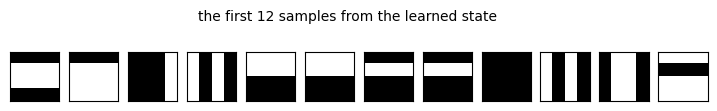

In [14]:
# ==============================================================================
# STEP 7: samples from the learned bars-and-stripes state
# ==============================================================================
M_BS = 200_000
t0 = time.perf_counter()
samples_bs = draw(30, As_bs0, M_BS)
t_bs = time.perf_counter() - t0
codes = bit_codes(samples_bs)
data_codes = bit_codes(V_BS)
in_data = np.isin(codes, data_codes)
counts_bs = np.array([np.sum(codes == c) for c in data_codes])
G_bs = g_statistic(counts_bs, np.full(30, 1 / 30))
print(f"{M_BS} samples in {t_bs:.1f} s;  samples that are training images: {in_data.sum()} of {M_BS}")
print(f"counts per image from {counts_bs.min()} to {counts_bs.max()} (expected {M_BS / 30:.0f})")
print(f"this run:      G = {G_bs:.1f},  D_KL = {G_bs / (2 * M_BS):.2e} (expected about 29/(2 M_s) = {29 / (2 * M_BS):.2e}),  "
      f"p-value (29 dof) = {chi2_dist.sf(G_bs, 29):.3f}")
print(f"[1], Sec. III A: G = 22.0,  D_KL = 1.10e-05 (expected about 29/(2 M_s) = {29 / 2e6:.2e} for M_s = 10^6),  p-value 0.820")

fig, axes = plt.subplots(1, 12, figsize=(9, 1.2))
show_images(axes, samples_bs[:12], BS_SIDE)
fig.suptitle("the first 12 samples from the learned state", fontsize=10, y=1.05)
plt.show()

All $2\times10^5$ samples are training images, and the statistic $G$ is of the size expected for 29 degrees of
freedom. Both values of $D_{\rm KL}$, ours and that of [[1]](#ref-1), lie near their expected values for their sample
sizes. A single run of the test gives one draw of a random p-value, uniformly distributed between 0 and 1 for a
correct sampler; our value and that of [[1]](#ref-1) are both unremarkable draws, and neither run rejects the uniform
distribution. Section 5 had already tested the sampler with an exact reference; here the test confirms that the
learned state and the sampler together reproduce the data distribution.

In [15]:
section_timer("7 MNIST")

## 7. Handwritten digits

### 7.1 Binarised MNIST at $14\times14$ pixels

[[1]](#ref-1), Sec. III C, trains on MNIST digits [[8]](#ref-8) turned into binary images by a threshold and put on the
chain row by row; its capacity experiments use $28\times28$ images, its generalisation study (Fig. 7) $14\times14$
images. We use the $14\times14$ MNIST file stored with this course (pixel values $0\dots255$ averaged over $2\times2$
blocks), and set a pixel to 1 if its value is at least 128 and to 0 otherwise. [[1]](#ref-1) does not state its
threshold or whether it binarised before or after the reduction, so our images can differ from its images in detail.
The training set has $N_{\rm T}=1000$ images, the training-set size of [[1]](#ref-1), Figs. 3–6 and the left panel of
Fig. 7; we take the first 1000 images of the file. The test set is the first 2000 test images ([[1]](#ref-1) uses
$10^4$).

Two reference models give the NLL values a scale. A uniform distribution over all strings has the NLL
$196\ln2\approx135.9$ for every image. The *independent-pixel model* $P(\mathbf v)=\prod_jp_j^{v_j}(1-p_j)^{1-v_j}$
has no correlations at all; it is the product state, an MPS with all $\chi_j=1$. Its maximum-likelihood marginals
$p_j$ are the fractions of training images with pixel $j$ equal to 1. Pixels that are never 1 in the training set
would then get $p_j=0$ and make the NLL of some test images infinite, so we use the smoothed estimate
$p_j=(n_j+1)/(N_{\rm T}+2)$, with $n_j$ the number of training images with pixel $j$ equal to 1. For every test NLL the
cell also prints the standard error of the mean over the 2000 test images, the standard deviation of $-\ln P$ divided
by $\sqrt{2000}$.

MNIST handwritten digits. Source: https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz. Licence: CC BY-SA 3.0. Reduced to 14x14 by 2x2 averaging; first 20000 training and all 10000 test images. See data/README.md.



fraction of pixels equal to 1: 0.126;  distinct images among the 1000 training images: 995
lower bound of the training NLL: H(p_hat) = 6.9003  (ln 1000 = 6.9078);  uniform distribution: 196 ln 2 = 135.9
pixels never equal to 1 in the training set: 61;  test images with such a pixel equal to 1: 18 of 2000
independent-pixel model: training NLL 48.96,  test NLL 48.84 +- 0.26 (standard error)


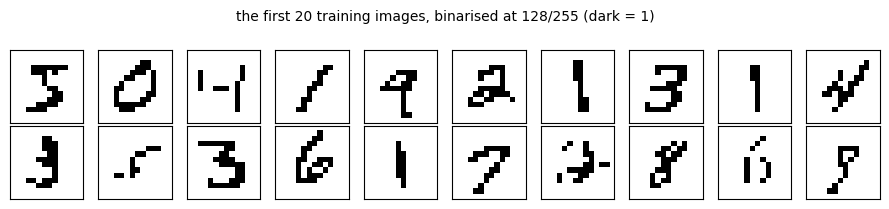

In [16]:
# ==============================================================================
# STEP 8: binarised 14 x 14 MNIST and the independent-pixel baseline
# ==============================================================================
MNIST = np.load("../data/mnist_14x14.npz")
print(str(MNIST["info"]))
SIDE, N_PIX, THRESHOLD = 14, 196, 128
X_ALL = (MNIST["x_train"].reshape(-1, N_PIX) >= THRESHOLD).astype(np.int32)
X_TEST = jnp.asarray((MNIST["x_test"][:2000].reshape(-1, N_PIX) >= THRESHOLD).astype(np.int32))
N_TEST = X_TEST.shape[0]
N_TRAIN = 1000
X_TRAIN = jnp.asarray(X_ALL[:N_TRAIN])
xt, xs = np.asarray(X_TRAIN), np.asarray(X_TEST)
_, cnt = np.unique(xt, axis=0, return_counts=True)
H_emp = float(-np.sum(cnt / N_TRAIN * np.log(cnt / N_TRAIN)))
print(f"\nfraction of pixels equal to 1: {xt.mean():.3f};  distinct images among the {N_TRAIN} training images: {len(cnt)}")
print(f"lower bound of the training NLL: H(p_hat) = {H_emp:.4f}  (ln {N_TRAIN} = {np.log(N_TRAIN):.4f});  "
      f"uniform distribution: {N_PIX} ln 2 = {N_PIX * np.log(2):.1f}")
never_on = ~xt.any(axis=0)
print(f"pixels never equal to 1 in the training set: {never_on.sum()};  test images with such a pixel equal to 1: "
      f"{int(xs[:, never_on].any(axis=1).sum())} of {N_TEST}")


def se_mean(x):
    """Standard error of the mean of the values x."""
    return float(np.std(x, ddof=1) / np.sqrt(len(x)))


P_PIX = (xt.sum(axis=0) + 1) / (N_TRAIN + 2)                             # smoothed marginals of the pixels


def nll_independent(v):
    """-ln P(v) of every string under the independent-pixel model with the marginals P_PIX."""
    return -(np.asarray(v) * np.log(P_PIX) + (1 - np.asarray(v)) * np.log(1 - P_PIX)).sum(axis=1)


nll_ind_train, nll_ind_test = nll_independent(xt), nll_independent(xs)
print(f"independent-pixel model: training NLL {nll_ind_train.mean():.2f},  test NLL {nll_ind_test.mean():.2f} "
      f"+- {se_mean(nll_ind_test):.2f} (standard error)")

fig, axes = plt.subplots(2, 10, figsize=(9, 2.1))
show_images(axes.flat, xt[:20], SIDE)
fig.suptitle(f"the first 20 training images, binarised at {THRESHOLD}/255 (dark = 1)", fontsize=10)
fig.tight_layout()
plt.show()

About an eighth of the pixels are 1. Five of the 1000 training images are duplicates of others, so the lower bound
of the training NLL is slightly below $\ln1000$. The independent-pixel model reaches a test NLL of $48.8$ nats
(printed above), far below the 135.9 of the uniform distribution: most of the gain over uniform comes from the
marginals alone, mainly from the white margins. An MPS with correlations must beat this baseline to be of any use.
Some pixels at the margins are never 1 in the training set; a model that follows the training data exactly gives zero
probability to any image with such a pixel, so a test NLL can be infinite, and the code reports how many test images
have $P=0$ and averages the NLL over the others.

### 7.2 Training and test likelihood during training

We train with $\chi_{\max}=32$, $\varepsilon_{\rm cut}=10^{-7}$ and one line-search step per bond for five loops, and
record after each loop the NLL of the training set and of the test set. In [[1]](#ref-1), Fig. 7, the test NLL of
the model trained on $10^3$ images first falls, to a minimum of $40.26$, and then rises while the training NLL keeps
falling (its value of $\chi_{\max}$ for this figure is not stated). Changes of the test NLL between loops are measured
on the same 2000 images, so their standard error is that of the per-image differences, much smaller than the
standard error of each mean.

In [17]:
# ==============================================================================
# STEP 9: chi_max = 32, 1000 training images, 5 loops
# ==============================================================================
CHI_MAIN, LOOPS = 32, 5
As_mn, hist_mn = train_born_machine(X_TRAIN, CHI_MAIN, LOOPS, v_test=X_TEST)
for k, h in enumerate(hist_mn):
    print(f"loop {k + 1}: training NLL {h['train']:.3f},  test NLL {h['test']:.3f} +- {se_mean(h['test_each']):.3f} "
          f"({h['test_zero']} with P = 0),  largest bond dimension {h['dims'].max()},  largest discarded weight "
          f"{h['eps']:.1e},  {h['time']:.1f} s")
best_mn = int(np.argmin([h["test"] for h in hist_mn]))
d_last = hist_mn[-1]["test_each"] - hist_mn[best_mn]["test_each"]
print(f"test NLL after loop {LOOPS} minus after loop {best_mn + 1}: {d_last.mean():.3f} +- {se_mean(d_last):.3f}")
nll_check = nll_of(As_mn, X_TRAIN)[0]
print(f"\ntraining NLL of the final MPS by full contraction: {nll_check:.6f}  (reported by the last bond update "
      f"{hist_mn[-1]['train']:.6f})")
assert abs(nll_check - hist_mn[-1]["train"]) < 1e-8 * nll_check

loop 1: training NLL 40.560,  test NLL 44.037 +- 0.234 (0 with P = 0),  largest bond dimension 8,  largest discarded weight 7.4e-15,  12.8 s
loop 2: training NLL 30.147,  test NLL 40.956 +- 0.292 (0 with P = 0),  largest bond dimension 32,  largest discarded weight 7.7e-15,  5.1 s
loop 3: training NLL 26.497,  test NLL 40.604 +- 0.350 (0 with P = 0),  largest bond dimension 32,  largest discarded weight 1.9e-02,  6.2 s
loop 4: training NLL 25.623,  test NLL 40.747 +- 0.380 (0 with P = 0),  largest bond dimension 32,  largest discarded weight 7.7e-03,  6.2 s
loop 5: training NLL 25.322,  test NLL 41.073 +- 0.397 (0 with P = 0),  largest bond dimension 32,  largest discarded weight 8.7e-03,  4.7 s
test NLL after loop 5 minus after loop 3: 0.469 +- 0.110



training NLL of the final MPS by full contraction: 25.322370  (reported by the last bond update 25.322370)


The training NLL falls from $40.6$ after the first loop to $25.3$ after the fifth and keeps falling; the test NLL
reaches its minimum, $40.60\pm0.35$, after the third loop and then rises. The rise to the fifth loop,
$0.47\pm0.11$ nats measured on the same test images, is four standard errors and therefore real: this is
overfitting, the behaviour of [[1]](#ref-1), Fig. 7, for $10^3$ training images, whose minimum $40.26$ lies within one
standard error of ours (with a different threshold, test set and, probably, $\chi_{\max}$). Already after one loop
the model beats the independent-pixel baseline, $48.8$, by about 5 nats on the test set, and at its best by 8 nats.
From the second loop on the largest bonds are at the cap, and the largest weight discarded by a split of the left
sweep is about $2\,\%$ in the third loop and below $1\,\%$ in the fourth and fifth: at $\chi_{\max}=32$ the model is limited by its bond dimension and
still far above the lower bound $\ln1000$. No test image has $P=0$ in this run, although 18 contain a pixel that is
never 1 in the training set: after five loops the model gives such pixels a small but non-zero probability. The NLL
from the full contraction equals the value reported by the sweep, which confirms the bookkeeping of the environment
norms.

### 7.3 Likelihood against bond dimension and training-set size

[[1]](#ref-1), Fig. 3, shows how the training NLL of a model of $10^3$ images of $28\times28$ pixels falls with
$\chi_{\max}$ and approaches $\ln N_{\rm T}$ at $\chi_{\max}\approx10^3$. We cover $\chi_{\max}=4$ to $32$ for the
$14\times14$ images, again five loops each, and also train with $N_{\rm T}=3000$ images at $\chi_{\max}=16$ to see how
a larger training set changes the test NLL ([[1]](#ref-1), Fig. 7, compares $10^3$, $10^4$ and $6\times10^4$ images).
The runs with $\chi_{\max}=4$, 8 and 16 share one storage width $\chi_{\rm s}=16$ and differ only in the traced cap.

chi_max =  4: training NLL  38.153,  test NLL after 5 loops  42.019 +- 0.281,  lowest  42.019 (loop 5),  P = 0 for 0 test images,   15.4 s
chi_max =  8: training NLL  32.639,  test NLL after 5 loops  39.980 +- 0.305,  lowest  39.980 (loop 5),  P = 0 for 0 test images,   12.2 s
chi_max = 16: training NLL  27.872,  test NLL after 5 loops  39.595 +- 0.360,  lowest  39.500 (loop 4),  P = 0 for 0 test images,   12.8 s
chi_max = 32: training NLL  25.322,  test NLL after 5 loops  41.073 +- 0.397,  lowest  40.604 (loop 3),  P = 0 for 0 test images,   35.0 s



N_T = 3000, chi_max = 16: loop 1: 43.29 / 43.85, loop 2: 35.03 / 38.45, loop 3: 32.00 / 36.38, loop 4: 31.09 / 35.96, loop 5: 30.71 / 35.74   (training / test NLL)
   test NLL after loop 5: 35.742 +- 0.260;  independent-pixel model: 48.84


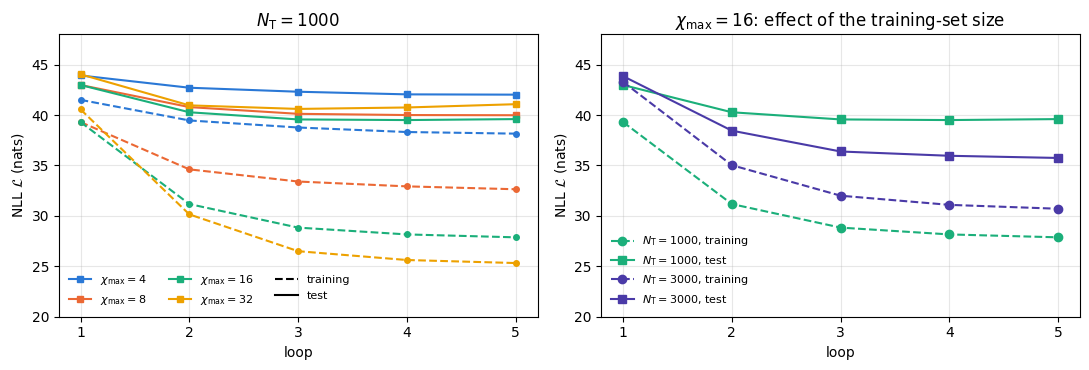

In [18]:
# ==============================================================================
# STEP 10: NLL against chi_max (1000 images) and against N_T (chi_max = 16)
# ==============================================================================
CHIS = (4, 8, 16, 32)
HIST_CHI = {CHI_MAIN: hist_mn}
for chi in CHIS[:-1]:
    _, HIST_CHI[chi] = train_born_machine(X_TRAIN, chi, LOOPS, chi_s=16, v_test=X_TEST)
for chi in CHIS:
    h = HIST_CHI[chi]
    best = int(np.argmin([e["test"] for e in h]))
    print(f"chi_max = {chi:2d}: training NLL {h[-1]['train']:7.3f},  test NLL after {LOOPS} loops {h[-1]['test']:7.3f} "
          f"+- {se_mean(h[-1]['test_each']):.3f},  lowest {h[best]['test']:7.3f} (loop {best + 1}),  P = 0 for "
          f"{h[-1]['test_zero']} test images,  {sum(e['time'] for e in h):5.1f} s")

N_TRAIN_BIG = 3000
As_big, hist_big = train_born_machine(jnp.asarray(X_ALL[:N_TRAIN_BIG]), 16, LOOPS, v_test=X_TEST)
print(f"\nN_T = {N_TRAIN_BIG}, chi_max = 16: " + ", ".join(f"loop {k + 1}: {h['train']:.2f} / {h['test']:.2f}"
                                                     for k, h in enumerate(hist_big)) + "   (training / test NLL)")
print(f"   test NLL after loop {LOOPS}: {hist_big[-1]['test']:.3f} +- {se_mean(hist_big[-1]['test_each']):.3f};  "
      f"independent-pixel model: {nll_ind_test.mean():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
loops = np.arange(1, LOOPS + 1)
for k, chi in enumerate(CHIS):
    axes[0].plot(loops, [e["train"] for e in HIST_CHI[chi]], "o--", color=PALETTE[k], ms=4)
    axes[0].plot(loops, [e["test"] for e in HIST_CHI[chi]], "s-", color=PALETTE[k], ms=4, label=rf"$\chi_{{\max}}={chi}$")
axes[0].plot([], [], "k--", label="training")
axes[0].plot([], [], "k-", label="test")
axes[0].set_xlabel("loop")
axes[0].set_ylabel(r"NLL $\mathcal{L}$ (nats)")
axes[0].set_title(r"$N_{\rm T}=1000$")
axes[0].legend(fontsize=8, ncol=3, loc="lower left")
axes[0].set_ylim(20, 48)
for ax in axes:
    ax.set_xticks(loops)
axes[1].plot(loops, [e["train"] for e in HIST_CHI[16]], "o--", color=PALETTE[2], label=r"$N_{\rm T}=1000$, training")
axes[1].plot(loops, [e["test"] for e in HIST_CHI[16]], "s-", color=PALETTE[2], label=r"$N_{\rm T}=1000$, test")
axes[1].plot(loops, [e["train"] for e in hist_big], "o--", color=PALETTE[5], label=rf"$N_{{\rm T}}={N_TRAIN_BIG}$, training")
axes[1].plot(loops, [e["test"] for e in hist_big], "s-", color=PALETTE[5], label=rf"$N_{{\rm T}}={N_TRAIN_BIG}$, test")
axes[1].set_xlabel("loop")
axes[1].set_ylabel(r"NLL $\mathcal{L}$ (nats)")
axes[1].set_title(r"$\chi_{\max}=16$: effect of the training-set size")
axes[1].legend(fontsize=8)
axes[1].set_ylim(20, 48)
fig.tight_layout()
plt.show()

**Interpretation.** A larger $\chi_{\max}$ lowers the training NLL at every loop: the bond dimension is the capacity
of the model, as in [[1]](#ref-1), Fig. 3. The test NLL improves with $\chi_{\max}$ only up to a point. At
$\chi_{\max}=4$ the model underfits: the training NLL is high and the test NLL only about 4 nats above it. At
$\chi_{\max}=8$, 16 and 32 the gap grows to 7, 12 and 16 nats. At 32 the test NLL passes through a minimum after
the third loop and rises again, by more than its uncertainty (Section 7.2): the model overfits. At 16 it is flat over
the last three loops, within 0.1 nats. The test NLL after five loops at $\chi_{\max}=16$, $39.60$, is lower than at
$\chi_{\max}=8$ by about $0.4$ nats, comparable to the standard error of either mean, about $0.3$: between 8 and 16
the bond dimension hardly matters for the test set at this training-set size.

With three times as many training images at the same $\chi_{\max}=16$, the training NLL is higher (the model has
more images to fit with the same capacity), the test NLL, $35.74\pm0.26$ after five loops, is lower than any value
reached with 1000 images and still falling, and the gap between the two is smaller, 5 nats. [[1]](#ref-1), Fig. 7,
shows the same trend with $10^4$ images, whose test NLL falls to $33.65$ and then rises only slowly; our five loops
with 3000 images stop before a minimum appears. More data push overfitting back, and the best test NLL decreases
with the size of the training set, as [[1]](#ref-1) states.

### 7.4 Where the bond dimension goes

The SVD split chooses every bond dimension. [[1]](#ref-1), Fig. 4, shows these bond dimensions as an image for a
model of $28\times28$ images with $\chi_{\max}=800$, with the bond to the right of each pixel drawn at that pixel.
The same map for our $\chi_{\max}=32$ model follows (bond $j$ drawn at pixel $j-1$), with the bond dimensions of the
$\chi_{\max}=4$ to 16 models along the chain; the cell also prints how many parameters the bond dimensions imply,
$\sum_j2\chi_j\chi_{j+1}$.

chi_max = 32: bonds at the cap: 60 of 195;  bonds with dimension <= 2: 25;  parameters 162676 (padded storage 401408)
bond dimension, mean over the bonds of each image row: [1.0, 4.1, 12.1, 21.7, 24.9, 23.4, 22.6, 22.6, 24.0, 23.9, 24.1, 19.7, 10.1, 3.4]
bond dimensions at the left and right margin pixels of rows 3-10: [7, 11, 12, 10, 10, 9, 11, 12] [12, 12, 10, 10, 9, 11, 12, 10]


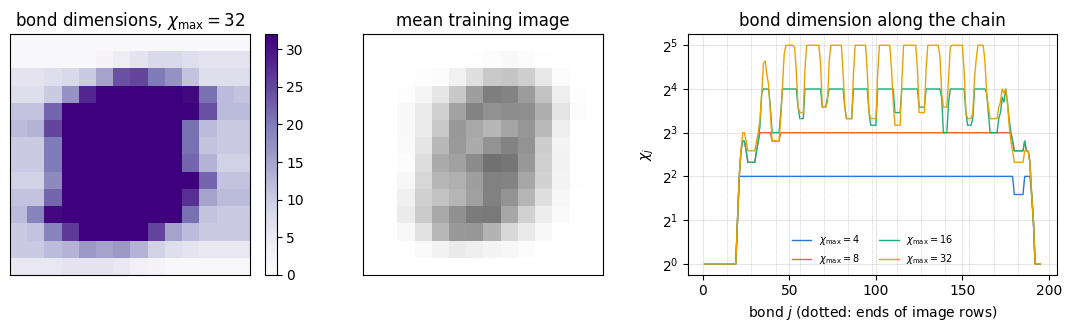

In [19]:
# ==============================================================================
# STEP 11: map of the learned bond dimensions
# ==============================================================================
dims_main = hist_mn[-1]["dims"]                                          # dims_main[k]: bond k + 1
dims_img = np.append(dims_main, 1).reshape(SIDE, SIDE)               # bond j at pixel j - 1 (its left neighbour)
chis_full = np.concatenate([[1], dims_main, [1]])
print(f"chi_max = 32: bonds at the cap: {int(np.sum(dims_main == CHI_MAIN))} of {N_PIX - 1};  bonds with dimension "
      f"<= 2: {int(np.sum(dims_main <= 2))};  parameters {int(np.sum(2 * chis_full[:-1] * chis_full[1:]))} "
      f"(padded storage {N_PIX * 2 * CHI_MAIN ** 2})")
print("bond dimension, mean over the bonds of each image row:", np.round(dims_img.mean(axis=1), 1).tolist())
print("bond dimensions at the left and right margin pixels of rows 3-10:",
      dims_img[3:11, 0].tolist(), dims_img[3:11, -2].tolist())

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), gridspec_kw=dict(width_ratios=[1, 1, 1.3]))
im = axes[0].imshow(dims_img, cmap="Purples", vmin=0, vmax=CHI_MAIN)
axes[0].set_title(r"bond dimensions, $\chi_{\max}=32$")
fig.colorbar(im, ax=axes[0], fraction=0.046)
axes[1].imshow(xt.mean(axis=0).reshape(SIDE, SIDE), cmap="gray_r", vmin=0, vmax=1)
axes[1].set_title("mean training image")
for ax in axes[:2]:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
for k, chi in enumerate(CHIS):
    axes[2].plot(np.arange(1, N_PIX), HIST_CHI[chi][-1]["dims"], color=PALETTE[k], lw=1, label=rf"$\chi_{{\max}}={chi}$")
for r in range(1, SIDE):
    axes[2].axvline(SIDE * r, color="0.7", lw=0.5, ls=":")
axes[2].set_yscale("log", base=2)
axes[2].set_xlabel("bond $j$ (dotted: ends of image rows)")
axes[2].set_ylabel(r"$\chi_j$")
axes[2].set_title("bond dimension along the chain")
axes[2].legend(fontsize=7, loc="lower center", ncol=2)
fig.tight_layout()
plt.show()

The bond dimensions follow the digits. They are 1 in the first image row, whose pixels are white in every image and
carry no information, small in the last rows, and at the cap in the middle of the image, where the strokes vary most.
At the left and right margins of the middle rows, whose pixels are white too, the bond dimensions are 7 to 12 (about
a third of the cap): smaller than in the centre but far larger than in the first row. These bonds carry the
correlations between one image row and the next, which pass through the whole row in the chain. [[1]](#ref-1),
Fig. 4, shows the same structure at its larger scale, with margin bonds of the middle rows at a similar fraction of
its cap. The adaptive split stores only the parameters the bond dimensions need, about 40 % of the padded array here.

### 7.5 Generated digits

[[1]](#ref-1), Fig. 5, shows samples of its $\chi_{\max}=800$ model: blank margins, pen strokes, a few recognisable
digits. The cell draws 5000 samples from the $\chi_{\max}=32$ model and shows 24 of them, with 24 samples of the
$N_{\rm T}=3000$, $\chi_{\max}=16$ model. From the samples it estimates the entropy of the model distribution,
$H(P)=\mathbb E_P[-\ln P]$, the mean NLL of the model's own samples. It also measures how close the samples are to the
training images: the Hamming distance (number of differing pixels) to the nearest training image, with the same
distance for test images as a reference, the number of samples that are training images, and the total probability
$\sum_{\mathbf v\in\mathcal T}P(\mathbf v)$ that the model gives to the training set.

entropy of the chi_max = 32 model from 5000 samples: 31.84 +- 0.10  (training NLL 25.32, test NLL 41.07)
pixels equal to 1 per sample: 24.9 (chi_max = 32), 25.0 (N_T = 3000);  per training image: 24.7


Hamming distance to the nearest training image, 200 strings each:  samples min 6, median 16;  test images min 0, median 10
samples equal to a training image: 0 of 5000;  total probability of the training set sum_T P(v) = 2.2e-05


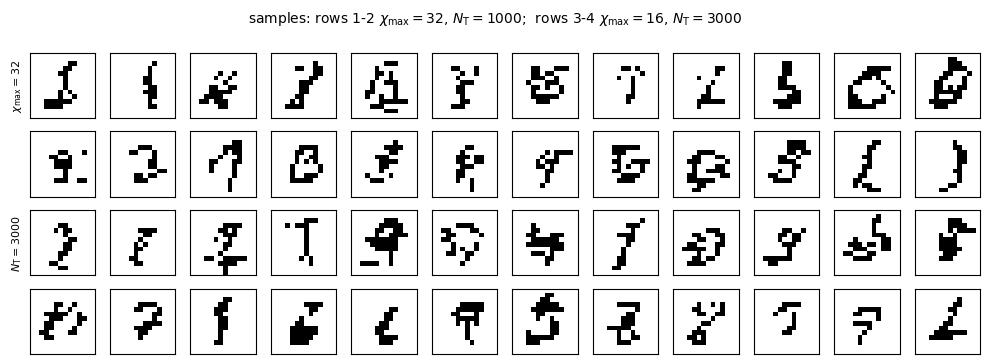

In [20]:
# ==============================================================================
# STEP 12: samples from the trained models
# ==============================================================================
gen_main = draw(40, As_mn, 5000)
gen_big = draw(41, As_big, 24)
nll_gen = -2 * np.asarray(log_psi(As_mn, jnp.asarray(gen_main)))           # Z = 1 after a loop
print(f"entropy of the chi_max = 32 model from 5000 samples: {nll_gen.mean():.2f} +- {se_mean(nll_gen):.2f}  "
      f"(training NLL {hist_mn[-1]['train']:.2f}, test NLL {hist_mn[-1]['test']:.2f})")
print(f"pixels equal to 1 per sample: {gen_main.sum(axis=1).mean():.1f} (chi_max = 32), {gen_big.sum(axis=1).mean():.1f} "
      f"(N_T = {N_TRAIN_BIG});  per training image: {xt.sum(axis=1).mean():.1f}")


def nearest_train_distance(v):
    """Hamming distance of each string to the nearest training image."""
    return np.array([np.abs(xt - s[None]).sum(axis=1).min() for s in np.asarray(v)])


d_gen, d_test = nearest_train_distance(gen_main[:200]), nearest_train_distance(xs[:200])
print(f"Hamming distance to the nearest training image, 200 strings each:  samples min {d_gen.min()}, median "
      f"{np.median(d_gen):.0f};  test images min {d_test.min()}, median {np.median(d_test):.0f}")
train_codes = {bytes(r.astype(np.uint8)) for r in xt}
n_copies = sum(bytes(r.astype(np.uint8)) in train_codes for r in gen_main)
P_train_total = float(np.sum(np.exp(2 * np.asarray(log_psi(As_mn, X_TRAIN)))))
print(f"samples equal to a training image: {n_copies} of {len(gen_main)};  total probability of the training set "
      f"sum_T P(v) = {P_train_total:.1e}")

fig, axes = plt.subplots(4, 12, figsize=(10, 3.7))
show_images(axes[:2].flat, gen_main, SIDE)
show_images(axes[2:].flat, gen_big, SIDE)
axes[0, 0].set_ylabel(r"$\chi_{\max}=32$", fontsize=8)
axes[2, 0].set_ylabel(rf"$N_{{\rm T}}={N_TRAIN_BIG}$", fontsize=8)
fig.suptitle(rf"samples: rows 1-2 $\chi_{{\max}}=32$, $N_{{\rm T}}=1000$;  rows 3-4 $\chi_{{\max}}=16$, $N_{{\rm T}}={N_TRAIN_BIG}$",
             fontsize=10)
fig.tight_layout()
plt.show()

The samples have blank margins, strokes of the right thickness and about the right number of black pixels. Some are
recognisable digits, many are fragments of strokes, as in [[1]](#ref-1), Fig. 5. The connection between rows is weak:
a stroke in one row often does not continue in the next, because every correlation between two rows has to pass
through all bonds of the row between them.

The numbers resolve how "overfitting" and "memorising" relate. The entropy of the model, $31.8$ nats, lies between
the training NLL, $25.3$, and the test NLL, $41.1$: on average the model gives a training image $e^{15.8}$ times the
probability of a test image, which is the overfitting of Section 7.3. Yet the whole training set together receives a
probability of only $2\times10^{-5}$, none of the 5000 samples is a training image, and the samples are even farther
from the nearest training image (median Hamming distance 16) than real test digits are (median 10). The model
favours its training images but is very far from having memorised them; a memorising model would give the training
set probability 1.

### 7.6 Reconstruction of missing pixels

[[1]](#ref-1), Fig. 6, removes 12 of the 28 columns or rows of an image and samples them conditioned on the rest. At
$14\times14$ pixels we remove 6 columns (left or right) or 6 rows (top or bottom), and reconstruct them with the
conditional sampler of Eq. (14), for 40 training and 40 test images. Each reconstruction is *one* sample of the
missing pixels from their conditional distribution; the most probable completion would be a different computation.
The fraction of wrong pixels in
the missing region is compared with two baselines on the same images: filling the region with white pixels, whose
error is the fraction of black pixels (the ink coverage) of the region, and drawing every missing pixel independently
from its marginal $p_j$, whose expected error is the mean of $v_j(1-p_j)+(1-v_j)p_j$.

fraction of wrong pixels in the missing region, mean +- standard error over 40 images:


  left 6 columns   train: MPS 0.060 +- 0.007;  all white (ink coverage) 0.074;  independent pixels 0.118
  left 6 columns   test : MPS 0.089 +- 0.008;  all white (ink coverage) 0.076;  independent pixels 0.120


  right 6 columns  train: MPS 0.085 +- 0.008;  all white (ink coverage) 0.114;  independent pixels 0.147
  right 6 columns  test : MPS 0.111 +- 0.009;  all white (ink coverage) 0.100;  independent pixels 0.148


  top 6 rows       train: MPS 0.116 +- 0.007;  all white (ink coverage) 0.105;  independent pixels 0.137
  top 6 rows       test : MPS 0.130 +- 0.007;  all white (ink coverage) 0.096;  independent pixels 0.140


  bottom 6 rows    train: MPS 0.150 +- 0.009;  all white (ink coverage) 0.118;  independent pixels 0.157
  bottom 6 rows    test : MPS 0.145 +- 0.008;  all white (ink coverage) 0.110;  independent pixels 0.157


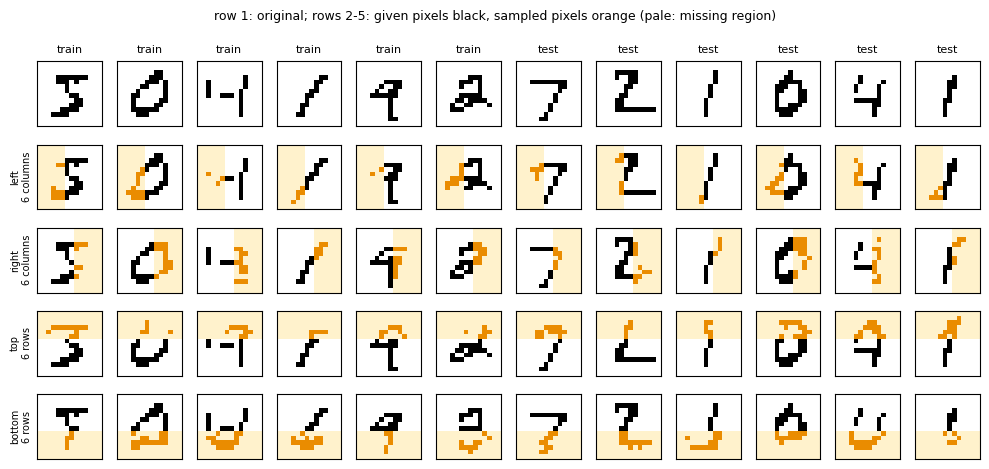

In [21]:
# ==============================================================================
# STEP 13: conditional sampling of missing columns and rows, with baselines
# ==============================================================================
rows_idx, cols_idx = np.divmod(np.arange(N_PIX), SIDE)
MASKS = {"left 6 columns": cols_idx < 6, "right 6 columns": cols_idx >= 8,
         "top 6 rows": rows_idx < 6, "bottom 6 rows": rows_idx >= 8}
N_REC = 40
IMGS = jnp.concatenate([X_TRAIN[:N_REC], X_TEST[:N_REC]])
imgs = np.asarray(IMGS)
recon = {}
print(f"fraction of wrong pixels in the missing region, mean +- standard error over {N_REC} images:")
for k, (name, missing) in enumerate(MASKS.items()):
    keys = jax.random.split(jax.random.PRNGKey(50 + k), IMGS.shape[0])
    recon[name] = np.asarray(sample_conditional_batch(keys, As_mn, IMGS, jnp.asarray(~missing)))
    assert np.all(recon[name][:, ~missing] == imgs[:, ~missing])
    err = (recon[name] != imgs)[:, missing].mean(axis=1)
    white = imgs[:, missing].mean(axis=1)
    marg = (imgs[:, missing] * (1 - P_PIX[missing]) + (1 - imgs[:, missing]) * P_PIX[missing]).mean(axis=1)
    for grp, sl in (("train", slice(0, N_REC)), ("test", slice(N_REC, None))):
        print(f"  {name:16s} {grp:5s}: MPS {err[sl].mean():.3f} +- {se_mean(err[sl]):.3f};  all white (ink coverage) "
              f"{white[sl].mean():.3f};  independent pixels {marg[sl].mean():.3f}")

fig, axes = plt.subplots(5, 12, figsize=(10, 4.8))
show_images(axes[0], np.concatenate([imgs[:6], imgs[N_REC:N_REC + 6]]), SIDE, titles=["train"] * 6 + ["test"] * 6)
for r, (name, missing) in enumerate(MASKS.items(), start=1):
    shown = np.concatenate([recon[name][:6], recon[name][N_REC:N_REC + 6]])
    for k, ax in enumerate(axes[r]):
        rgb = np.ones((N_PIX, 3))
        rgb[(~missing) & (shown[k] == 1)] = 0.0
        rgb[missing & (shown[k] == 1)] = [0.92, 0.55, 0.0]
        rgb[missing & (shown[k] == 0)] = [1.0, 0.95, 0.80]
        ax.imshow(rgb.reshape(SIDE, SIDE, 3))
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
    axes[r, 0].set_ylabel(name.replace(" ", "\n", 1), fontsize=7)
fig.suptitle("row 1: original; rows 2-5: given pixels black, sampled pixels orange (pale: missing region)", fontsize=9)
fig.tight_layout()
plt.show()

The known pixels are never changed, and the sampled pixels continue the strokes into the missing region with
plausible, though not always correct, shapes. The pixel error is a harsh measure for a single sample: a stroke drawn
one pixel off counts twice, while the all-white guess makes no error on the background and pays only the ink
coverage. The MPS beats the independent-pixel baseline for every mask and both image groups. It beats the all-white
guess only for missing columns of training images; for test images and for missing rows its single samples have more
wrong pixels than the white guess. Relative to the ink coverage, missing columns are filled better than missing rows,
as [[1]](#ref-1), Fig. 6, observed and explained by the row-by-row order: a missing column leaves the known part of
every row next to the missing part in the chain, whereas a missing block of rows must be generated from correlations
that span whole rows. For three of the four masks the training images are reconstructed better than the test images,
by 1.4 to 2.7 combined standard errors, a further trace of the overfitting of Section 7.3; for the bottom rows there
is no difference.

In [22]:
section_timer("8 autodiff")

## 8. Training by automatic differentiation

The NLL (5) can also be minimised by differentiating the whole contraction with `jax.grad` and Adam
[[9]](#ref-9): $\ln Z$ from the transfer matrices (3), $\ln\vert\psi\vert$ from
`log_psi`, both differentiable, all tensors updated at once, mini-batches of 100 images, a fixed bond dimension
$\chi=16$ in the bulk and no SVD. The initial state is the same kind of random right-canonical MPS, now with all inner
bonds of dimension 16, because nothing would make the bond dimensions grow. We compare with the sweep at
$\chi_{\max}=16$ of Section 7.3, pass by pass: one epoch of Adam visits every training image once, and one loop of
sweeps updates every bond twice, each time with all training images. The cell also prints the time per pass in steady state, without compilation and without the
evaluation of the NLL after each pass.

Adam, epoch 1: training NLL 52.291,  test NLL 53.365,  7.0 s (cumulative 7.0 s)
Adam, epoch 2: training NLL 49.617,  test NLL 50.833,  1.1 s (cumulative 8.1 s)
Adam, epoch 3: training NLL 48.216,  test NLL 49.500,  0.8 s (cumulative 8.8 s)
Adam, epoch 4: training NLL 46.568,  test NLL 48.090,  1.1 s (cumulative 9.9 s)
sweeps, chi_max = 16:  loop 1 (2.5 s) training 39.302 / test 42.977;  loop 5 (cumulative 12.8 s) training 27.872 / test 39.595
steady state: 1.0 s per Adam epoch, 2.6 s per sweep loop


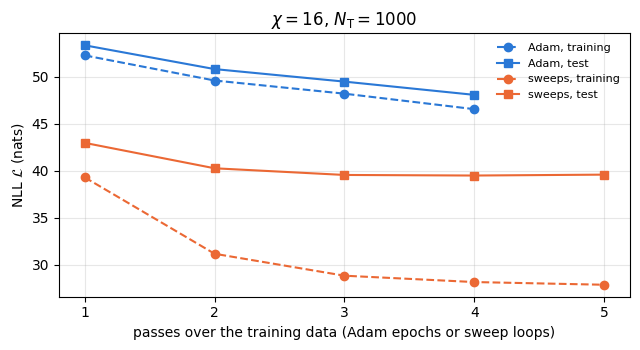

In [23]:
# ==============================================================================
# STEP 14: Adam on the full NLL, chi = 16, 1000 images, 4 epochs
# ==============================================================================
CHI_AD, BATCH, EPOCHS = 16, 100, 4
mask_ad = jnp.ones((N_PIX, CHI_AD, 2, CHI_AD), RDTYPE).at[0, 1:].set(0.0).at[-1, :, :, 1:].set(0.0)


def nll_full(As, v):
    """Eq. (5) with Z from Eq. (3); the boundary rows / columns are masked so they stay zero."""
    As = As * mask_ad
    return log_Z_transfer(As) - 2 * jnp.mean(log_psi(As, v))


@jax.jit
def adam_epoch(As, state, key, lr):
    """One pass over the training images in shuffled mini-batches; lax.scan over the batches."""
    order = jax.random.permutation(key, N_TRAIN).reshape(-1, BATCH)

    def step(carry, idx):
        As, state = carry
        val, g = jax.value_and_grad(nll_full)(As, X_TRAIN[idx])
        As, state = adam_update(As, g, state, lr=lr)
        return (As, state), val
    (As, state), vals = lax.scan(step, (As, state), order)
    return As, state, jnp.mean(vals)


As_ad = init_born_mps(60, N_PIX, CHI_AD, chi_init=CHI_AD)
state = adam_init(As_ad)
t_train, hist_ad = 0.0, []
for ep, k in enumerate(jax.random.split(jax.random.PRNGKey(61), EPOCHS)):
    t0 = time.perf_counter()
    As_ad, state, _ = adam_epoch(As_ad, state, k, 0.01)
    jax.block_until_ready(As_ad)
    t_ep = time.perf_counter() - t0
    t_train += t_ep
    hist_ad.append((t_train, t_ep, float(nll_full(As_ad, X_TRAIN)), nll_of(As_ad * mask_ad, X_TEST)[0]))
for ep in range(EPOCHS):
    print(f"Adam, epoch {ep + 1}: training NLL {hist_ad[ep][2]:.3f},  test NLL {hist_ad[ep][3]:.3f},  "
          f"{hist_ad[ep][1]:.1f} s (cumulative {hist_ad[ep][0]:.1f} s)")
t_sw = np.cumsum([e["time"] for e in HIST_CHI[16]])
print(f"sweeps, chi_max = 16:  loop 1 ({HIST_CHI[16][0]['time']:.1f} s) training {HIST_CHI[16][0]['train']:.3f} / test "
      f"{HIST_CHI[16][0]['test']:.3f};  loop {LOOPS} (cumulative {t_sw[-1]:.1f} s) training "
      f"{HIST_CHI[16][-1]['train']:.3f} / test {HIST_CHI[16][-1]['test']:.3f}")
print(f"steady state: {np.mean([e[1] for e in hist_ad[1:]]):.1f} s per Adam epoch, "
      f"{np.mean([e['time'] for e in HIST_CHI[16][1:]]):.1f} s per sweep loop")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ep_ax = np.arange(1, EPOCHS + 1)
ax.plot(ep_ax, [e[2] for e in hist_ad], "o--", color=PALETTE[0], label="Adam, training")
ax.plot(ep_ax, [e[3] for e in hist_ad], "s-", color=PALETTE[0], label="Adam, test")
ax.plot(loops, [e["train"] for e in HIST_CHI[16]], "o--", color=PALETTE[1], label="sweeps, training")
ax.plot(loops, [e["test"] for e in HIST_CHI[16]], "s-", color=PALETTE[1], label="sweeps, test")
ax.set_xticks(loops)
ax.set_xlabel("passes over the training data (Adam epochs or sweep loops)")
ax.set_ylabel(r"NLL $\mathcal{L}$ (nats)")
ax.set_title(r"$\chi=16$, $N_{\rm T}=1000$")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The sweeps win clearly per pass: after one loop they have a lower training and test NLL than Adam after four epochs,
and in steady state a sweep loop takes two to four times as long as an Adam epoch in our runs (timings vary on a
shared CPU), so at equal time the sweep is still ahead. Two differences explain the gap. Each bond update of the sweep chooses its step by the exact line search
of Section 4.4 on all training images, while Adam takes many small steps with one learning rate ($10^{-2}$, untuned).
And the sweep starts from bond dimension 2 and lets the SVD split add directions where the data need them, while the
gradient method has to shape all directions of a full $\chi=16$ state from a random start. The gradient method has
its own advantages: no SVD, any cost function, and a code that is the same for any network that `jax.grad` can
differentiate.

In [24]:
section_timer("9 entanglement")

## 9. Entanglement of the learned states and of the data

The *data state* of a training set is the state whose Born distribution is exactly the empirical one,
$\vert\psi_{\hat p}\rangle=\sum_{\mathbf v}\sqrt{\hat p(\mathbf v)}\,\vert\mathbf v\rangle$; for bars and stripes it is
Eq. (15). Its entanglement entropy across a bond, $S=-\sum_k\lambda_k^2\ln\lambda_k^2$ in nats, is computed by
`data_state_profile` of Section 6.1, together with the number of blocks. For the trained MPS, which after a loop is
right-canonical with the centre on site 0, one sweep of SVDs from the left gives the Schmidt values of every bond:
the singular values of the centre at each bond. The cell checks this profile against the
dense state of the learned bars-and-stripes MPS, then compares the learned states with their data states and with
the bound $\ln\chi_{\max}$.

bars and stripes: max |lambda^2 (MPS sweep) - lambda^2 (dense SVD)| = 1.9e-15
entropy (nats) across bonds 1..15, data state (15):  [0.693, 1.273, 1.806, 1.922, 2.292, 2.292, 2.292, 1.922, 2.292, 2.292, 2.292, 1.922, 1.806, 1.273, 0.693]
   learned state 0: largest S_learned - S_data = 0.370 at bond 4
   learned state 1: largest S_learned - S_data = 0.370 at bond 8
   learned state 2: largest S_learned - S_data = 0.370 at bond 4
   learned state 3: largest S_learned - S_data = 0.000



MNIST data state of 1000 images: Schmidt values and blocks of all 195 bonds in 5.1 s
data state: entropy at bonds 42, 56, 98, 140, 168: [2.22, 4.88, 6.78, 5.69, 1.17];  bonds with S >= 6.4 nats: 57, from bond 73 to 129
number of blocks at bonds 42, 98, 154: [65, 912, 131]  (bound on the bond dimension of any state supported exactly on the training set)
largest entropy: data state 6.780 (ln 1000 = 6.908);  learned chi_max = 32: 3.084 (ln 32 = 3.466);  learned N_T = 3000, chi_max = 16: 2.437 (ln 16 = 2.773)


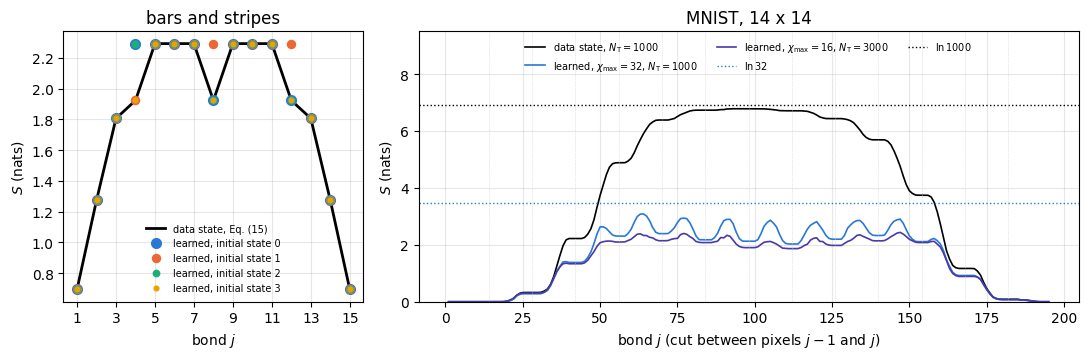

In [25]:
# ==============================================================================
# STEP 15: Schmidt profiles of the learned states and of the data states
# ==============================================================================
def mps_schmidt_profile(As):
    """Squared Schmidt values across every bond of a right-canonical MPS with a normalised centre on site 0.

    MATH            C = A_0;  for j = 0..N-2:  C[(a s), b] = U diag(lambda) V^T,  weights = lambda^2;  C <- diag(lambda) V^T A_{j+1}
    RETURNS         list of N-1 arrays (bond k at index k-1)
    """
    As = np.asarray(As)
    C, out = As[0], []
    for j in range(As.shape[0] - 1):
        a, s, b = C.shape
        U, lam, Vt = np.linalg.svd(C.reshape(a * s, b), full_matrices=False)
        out.append(lam[lam > 1e-12] ** 2)
        C = np.einsum("k,kb,bsc->ksc", lam, Vt, As[j + 1])
    return out


# CHECKPOINT: profile of the learned bars-and-stripes state against the dense SVD of its 2^16 vector
prof_bs = mps_schmidt_profile(As_bs0)
psi_n = psi_learned / np.linalg.norm(psi_learned)
err_prof = 0.0
for cut in range(1, N_BS):
    sv = np.linalg.svd(psi_n.reshape(2 ** cut, -1), compute_uv=False) ** 2
    m = len(prof_bs[cut - 1])
    err_prof = max(err_prof, np.max(np.abs(sv[:m] - prof_bs[cut - 1])), np.sum(sv[m:]))
print(f"bars and stripes: max |lambda^2 (MPS sweep) - lambda^2 (dense SVD)| = {err_prof:.1e}")
assert err_prof < 1e3 * TOL
print("entropy (nats) across bonds 1..15, data state (15): ", np.round(S_BS, 3).tolist())
S_BS_RUNS = {}
for seed in range(4):
    S_BS_RUNS[seed] = np.array([entropy_nats(w) for w in mps_schmidt_profile(BS_RUNS[seed][0])])
    dS = S_BS_RUNS[seed] - np.array(S_BS)
    where = f" at bond {int(np.argmax(dS)) + 1}" if dS.max() > 1e-8 else ""
    print(f"   learned state {seed}: largest S_learned - S_data = {dS.max():.3f}{where}")

S_main = np.array([entropy_nats(w) for w in mps_schmidt_profile(As_mn)])
S_big = np.array([entropy_nats(w) for w in mps_schmidt_profile(As_big)])
t0 = time.perf_counter()
prof_data, BLOCKS_MN = data_state_profile(xt)
S_data = np.array([entropy_nats(w) for w in prof_data])
print(f"\nMNIST data state of 1000 images: Schmidt values and blocks of all 195 bonds in {time.perf_counter() - t0:.1f} s")
print(f"data state: entropy at bonds 42, 56, 98, 140, 168: {np.round(S_data[[41, 55, 97, 139, 167]], 2).tolist()};  "
      f"bonds with S >= 6.4 nats: {int(np.sum(S_data >= 6.4))}, from bond {int(np.argmax(S_data >= 6.4)) + 1} to "
      f"{int(N_PIX - 1 - np.argmax(S_data[::-1] >= 6.4))}")
print(f"number of blocks at bonds 42, 98, 154: {BLOCKS_MN[[41, 97, 153]].tolist()}  (bound on the bond dimension of any "
      f"state supported exactly on the training set)")
print(f"largest entropy: data state {S_data.max():.3f} (ln 1000 = {np.log(1000):.3f});  learned chi_max = 32: "
      f"{S_main.max():.3f} (ln 32 = {np.log(32):.3f});  learned N_T = {N_TRAIN_BIG}, chi_max = 16: {S_big.max():.3f} "
      f"(ln 16 = {np.log(16):.3f})")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), gridspec_kw=dict(width_ratios=[1, 2.2]))
axes[0].plot(np.arange(1, N_BS), S_BS, "k-", lw=2, label="data state, Eq. (15)")
for seed in range(4):
    axes[0].plot(np.arange(1, N_BS), S_BS_RUNS[seed], "o", color=PALETTE[seed], ms=7 - 1.2 * seed,
                 label=f"learned, initial state {seed}")
axes[0].set_xticks(range(1, N_BS, 2))
axes[0].set_xlabel("bond $j$")
axes[0].set_ylabel("$S$ (nats)")
axes[0].set_title("bars and stripes")
axes[0].legend(fontsize=7)
bonds = np.arange(1, N_PIX)
axes[1].plot(bonds, S_data, "k-", lw=1.2, label=r"data state, $N_{\rm T}=1000$")
axes[1].plot(bonds, S_main, color=PALETTE[0], lw=1.2, label=r"learned, $\chi_{\max}=32$, $N_{\rm T}=1000$")
axes[1].plot(bonds, S_big, color=PALETTE[5], lw=1.2, label=rf"learned, $\chi_{{\max}}=16$, $N_{{\rm T}}={N_TRAIN_BIG}$")
axes[1].axhline(np.log(32), color=PALETTE[0], ls=":", lw=1, label=r"$\ln 32$")
axes[1].axhline(np.log(1000), color="k", ls=":", lw=1, label=r"$\ln 1000$")
for r in range(1, SIDE):
    axes[1].axvline(SIDE * r, color="0.8", lw=0.5, ls=":")
axes[1].set_xlabel("bond $j$ (cut between pixels $j-1$ and $j$)")
axes[1].set_ylabel("$S$ (nats)")
axes[1].set_title("MNIST, 14 x 14")
axes[1].legend(fontsize=7, loc="upper center", ncol=3)
axes[1].set_ylim(0, 9.5)
fig.tight_layout()
plt.show()

**Interpretation.** The Schmidt values obtained by the sweep agree with the dense SVD of the learned
bars-and-stripes state. The run whose stripe signs factorise over the rows (initial state 3) has the entanglement
profile of the data state (15) at every bond. The others have a larger entropy at the row boundaries where their
stripe sign table has rank 2 (Section 6.2), by $0.370$ nats in these runs, although all four give exactly the same
probabilities. The size of the excess is set by the singular values of the sign table, and tables of equal rank can
give different excesses.

For MNIST the data state of 1000 images has an entropy close to $\ln1000\approx6.9$ nats, at least $6.4$ nats,
only at the bonds inside image rows 5 to 9 (bonds 73 to 129); it is lower towards the top and bottom of the image,
where most pixels are white, for example $2.22$ at bond 42 and $1.17$ at bond 168. In the middle the halves of
different images are almost all different, so each image contributes its own Schmidt value.
The learned states peak at $3.08$ nats
($\chi_{\max}=32$, 89 % of $\ln32$) and $2.44$ nats ($N_{\rm T}=3000$, $\chi_{\max}=16$, 88 % of $\ln16$), far
below the data state.

The block count turns this into a statement about probabilities. At bond 98 the 995 distinct training images form 912
blocks. Any state whose support is exactly the training set, with every training image at $P>0$, has a coefficient
matrix with this block structure and at least one non-zero entry per block, so its Schmidt rank at bond 98 is at
least 912. A model with $\chi_{\max}=32$ and a finite training NLL gives every training image $P>0$, so it cannot be
supported on the training set alone: it must put probability on other strings. Section 7.5 measured how much: the
training set receives only $2\times10^{-5}$ of the probability. The bond dimension does not decide where the rest
goes; the training decides that, and the test NLL of Section 7.3 shows that a good part of it lands near real digits.

In [26]:
section_timer("10 cost")

## 10. Cost of the computation

| operation | cost | here |
|---|---|---|
| $\ln\psi(\mathbf v)$ of one string | $O(N\chi^2)$ | `log_psi`, Section 4 |
| $Z$ by transfer matrices | $O(N\chi^3)$ | Eq. (3) |
| $Z$ in mixed-canonical form | $O(\chi^2)$ | Eq. (4) |
| one bond update: environments, gradient, line search | $O(N_{\rm T}\chi^2)$ | Eqs. (7)–(9) |
| one bond update: SVD split | $O(\chi^3)$ | Eq. (10) |
| one loop (two sweeps) | $O(N(N_{\rm T}\chi^2+\chi^3))$ | Section 4.7 |
| cached environments | $2NN_{\rm T}\chi$ numbers | Section 4.6 |
| one sample | $O(N\chi^2)$ | Eq. (13) |
| one conditional sample | $O(N\chi^3)$ | Eq. (14) |

[[1]](#ref-1), Sec. II D, quotes $O(N_{\rm T}N\chi_{\max}^3)$ for the training; with one environment vector per
example, as here, the data enter with $\chi^2$ and only the SVDs with $\chi^3$. The cell prints the memory of the
cached environments of the largest runs, the time per loop and the wall-clock time of every section.

In [27]:
# ==============================================================================
# STEP 16: memory and time per section
# ==============================================================================
env_numbers = 2 * N_PIX * N_TRAIN_BIG * 16
print(f"cached environments, N_T = {N_TRAIN_BIG}, chi_s = 16: {env_numbers} numbers = {env_numbers * 8 / 1e6:.0f} MB "
      f"in double precision;  N_T = 1000, chi_s = 32: {2 * N_PIX * N_TRAIN * 32 * 8 / 1e6:.0f} MB")
print(f"mean time per loop (first loop excluded: compilation): chi_max = 32, N_T = 1000: "
      f"{np.mean([h['time'] for h in hist_mn[1:]]):.1f} s;  chi_max = 16, N_T = 1000: "
      f"{np.mean([h['time'] for h in HIST_CHI[16][1:]]):.1f} s;  chi_max = 16, N_T = {N_TRAIN_BIG}: "
      f"{np.mean([h['time'] for h in hist_big[1:]]):.1f} s")
section_timer("end")
print("\nwall-clock time per section:")
for k, v in SECTION_TIMES.items():
    if k != "end":
        print(f"   {k:24s} {v:6.1f} s")
print(f"   {'total (Sections 3-10)':24s} {sum(v for k, v in SECTION_TIMES.items() if k != 'end'):6.1f} s")

cached environments, N_T = 3000, chi_s = 16: 18816000 numbers = 151 MB in double precision;  N_T = 1000, chi_s = 32: 100 MB
mean time per loop (first loop excluded: compilation): chi_max = 32, N_T = 1000: 5.6 s;  chi_max = 16, N_T = 1000: 2.6 s;  chi_max = 16, N_T = 3000: 7.8 s

wall-clock time per section:
   3 model                     2.7 s
   4 learning                  6.8 s
   5 sampling                 18.9 s
   6 bars and stripes         25.4 s
   7 MNIST                   197.7 s
   8 autodiff                 19.2 s
   9 entanglement              8.3 s
   10 cost                     0.1 s
   total (Sections 3-10)     279.2 s


The time per loop grows roughly in proportion to $N_{\rm T}$ (a factor of 2.5 to 3.5 for three times as many images)
and by a factor of 2 to 3 from $\chi_{\max}=16$ to $32$ in our runs; the wall-clock times are those of a shared CPU
and vary between runs. The MNIST experiments of Section 7 dominate the total time.

## 11. Limits of the method

* **One dimension for two-dimensional data.** The chain orders the pixels row by row. Correlations between vertically
  neighbouring pixels pass through a whole row of bonds, which shows in the generated digits (Section 7.5) and in the
  reconstruction of missing rows (Section 7.6). [[1]](#ref-1), Sec. IV, names projected entangled pair states as the
  two-dimensional alternative, at the price of a harder contraction and the loss of the convenient canonical forms.
* **Capacity against generalisation.** The bond dimension sets the capacity. Too small, and the model underfits;
  larger, and the training NLL keeps falling while the test NLL rises (Section 7.3). The number of loops,
  $\chi_{\max}$ and $\varepsilon_{\rm cut}$ have to be chosen on held-out data.
* **Zero probabilities.** A model trained to the data gives zero probability to anything it has not seen; one
  unusual pixel makes the NLL of a test image infinite (Section 7.1).
* **Signs.** The NLL ignores the signs of the amplitudes, but the entanglement and the bond dimensions do not
  (Section 6.2); nothing in the training prefers the sign pattern with the least entanglement.
* **Cost.** The training cost grows with $N_{\rm T}\chi^2$ per bond; the larger bond dimensions of [[1]](#ref-1)
  ($\chi_{\max}$ up to 800) and the full training set of 60000 images are far beyond the few minutes of one CPU used
  here.
* **A classical model.** Everything runs on a CPU, and nothing in it demonstrates a quantum advantage. The model is a
  quantum state, and [[1]](#ref-1), Sec. IV, points out that tensor-network states that can be prepared by a quantum
  circuit could be sampled by measuring a quantum device.

## 12. Key takeaways

* **The model.** A real wave function $\psi(\mathbf v)$ stored as an MPS defines the distribution
  $P(\mathbf v)=\psi(\mathbf v)^2/Z$ over bit strings; $Z$ is a contraction of cost $O(N\chi^3)$, and in mixed-canonical
  form it is the squared norm of the centre tensor (Eqs. (1)–(4)).
* **Training.** The negative log-likelihood is the entropy of the data plus the Kullback–Leibler divergence of the
  model from them. Its gradient with respect to a two-site bond tensor is exact, $2B/Z$ minus a sum over the examples
  of environment outer products (Eq. (8), checked against `jax.grad`); it is orthogonal to $B$, so the step can be
  chosen by an exact line search on a great circle.
* **Adaptive bond dimensions.** The SVD split with a relative cutoff lets every bond dimension follow the data. The
  number of blocks of the data across a bond bounds the bond dimension of any exact model; for bars and stripes it is
  reached when the signs of the stripe images factorise over the rows.
* **Exact samples.** In right-canonical form a sample costs $O(N\chi^2)$ and is independent of all others; with fixed
  bits, a ladder of transfer matrices gives exact conditional samples in $O(N\chi^3)$ (checked against exact
  distributions by the total variation distance and the likelihood-ratio test).
* **Results.** Bars and stripes are learned exactly in four loops, with the minimal bond dimensions for one of four
  initial states, and $2\times10^5$ samples pass the likelihood-ratio test, as in [[1]](#ref-1). On binarised
  $14\times14$ MNIST with 1000 images the test NLL beats the independent-pixel baseline by 8 to 9 nats, reaches a
  minimum within one standard error of the value of [[1]](#ref-1) and then rises (overfitting); 3000 images give a
  lower test NLL.
* **Entanglement and memorisation.** The superposition of the 1000 MNIST training images needs hundreds of Schmidt
  values across the middle bonds; a model with $\chi_{\max}=32$ cannot represent it and puts almost all of its
  probability on strings outside the training set. The sign freedom of the amplitudes can add entanglement without
  changing any probability.

## 13. Exercises

1. ★ **The lower bound.** Show that $\mathcal L\geq H(\hat p)$ with equality only for $P=\hat p$ (use $\ln x\leq x-1$
   on Eq. (6)). Compute $H(\hat p)$ for a training set in which one image appears twice and all others once.
2. ★ **Learning rate against line search.** Replace `great_circle_step` by a plain gradient step
   $B\leftarrow B-\eta\Gamma$ as in [[1]](#ref-1), Appendix B (normalise afterwards, so that $Z=1$ stays valid), and
   train on bars and stripes for $\eta=0.05$, $0.2$ and $0.5$. Which values converge to $\ln30$, and how fast?
3. ★ **Testing a wrong sampler.** In `sample_conditional`, replace the environment $F^{[k+1]}$ by the identity and
   repeat the second checkpoint of Section 5. By how many standard deviations does the total variation distance now
   exceed its sampling spread?
4. ★★ **Signs and blocks (physics).** For the bars-and-stripes state $\sum_{\mathbf v}\sigma(\mathbf v)\vert\mathbf v\rangle$,
   show that the signs of the 14 bar images other than all white and all black do not change the Schmidt values at
   bonds 4, 8 and 12, and that the rank at bond 8 is 14 plus the rank of the $4\times4$ stripe sign matrix of
   Section 6.2. Prove that the ranks at bonds 4, 8 and 12 are all 15 exactly when the stripe signs factorise over the
   rows. Then compute the ranks at every bond for ten random sign patterns on the stripes only.
5. ★★ **Pixel orderings (extend the code).** Train the $\chi_{\max}=16$ model with the pixels in column-by-column order
   and in a snake order (rows alternately left to right and right to left), and compare the test NLL, the bond
   dimension map and the reconstruction of missing rows and columns.
6. ★★ **Early stopping.** Train with $\chi_{\max}=32$ for twelve loops, keep the model with the lowest NLL on a
   validation set of 1000 further training images, and report its NLL on the test set. Why must the validation set be
   different from the test set?
7. ★★ **Random patterns.** [[1]](#ref-1), Sec. III B, trains on $N_{\rm T}$ random strings of $N=20$ bits and finds
   $\mathcal L=\ln N_{\rm T}$ as long as $N_{\rm T}\leq\chi_{\max}$ (its Fig. 2(a)). Reproduce this for
   $\chi_{\max}=4,8,16$ and explain the threshold with the number of blocks of the data at the middle bond.
8. ★★★ **Anomaly detection.** Train a model on the 1000 images of one digit only and compute the NLL of test images
   of every digit. Plot the histograms per digit (compare [[1]](#ref-1), Fig. 8), and use the NLL with a threshold as
   a detector of "not this digit".

## References

<span id="ref-1">[1]</span> Z.-Y. Han, J. Wang, H. Fan, L. Wang and P. Zhang, *Unsupervised generative modeling using
matrix product states*, Phys. Rev. X **8**, 031012 (2018), arXiv:1709.01662 — the MPS Born machine: the Born-rule
model (Eq. (1)), the MPS (Eqs. (2)–(3)), the NLL (Eq. (4)) and its gradient with respect to a two-site tensor (Eq. (5),
Appendix B, Eqs. (B1)–(B5)), the canonical form and $Z$ (Appendix A), direct and conditional sampling (Sec. II C,
Eqs. (6)–(9)), costs (Sec. II D), bars and stripes with $10^6$ samples and the likelihood-ratio test (Sec. III A,
Fig. 1), random patterns (Sec. III B, Fig. 2), MNIST capacity, bond dimensions, samples, reconstruction and
generalisation (Sec. III C, Figs. 3–8), signs and two-dimensional networks (Sec. IV).

<span id="ref-2">[2]</span> M. Born, *Zur Quantenmechanik der Stoßvorgänge*, Z. Phys. **37**, 863 (1926) — the Born
rule.

<span id="ref-3">[3]</span> S. Kullback and R. A. Leibler, *On information and sufficiency*, Ann. Math. Statist.
**22**, 79 (1951) — the Kullback–Leibler divergence.

<span id="ref-4">[4]</span> C. Eckart and G. Young, *The approximation of one matrix by another of lower rank*,
Psychometrika **1**, 211 (1936) — optimality of the truncated SVD.

<span id="ref-5">[5]</span> S. R. White, *Minimally entangled typical quantum states at finite temperature*, Phys.
Rev. Lett. **102**, 190601 (2009), arXiv:0902.4475 — the sequential measurement of the sites of an MPS with the
Born probabilities, in one half-sweep (Eq. (7) and the text around it).

<span id="ref-6">[6]</span> A. J. Ferris and G. Vidal, *Perfect sampling with unitary tensor networks*, Phys. Rev. B
**85**, 165146 (2012), arXiv:1201.3974 — direct sampling of configurations of unitary tensor networks without a
Markov chain.

<span id="ref-7">[7]</span> S. S. Wilks, *The large-sample distribution of the likelihood ratio for testing composite
hypotheses*, Ann. Math. Statist. **9**, 60 (1938) — the chi-squared distribution of the likelihood-ratio statistic.

<span id="ref-8">[8]</span> Y. LeCun, L. Bottou, Y. Bengio and P. Haffner, *Gradient-based learning applied to document
recognition*, Proc. IEEE **86**, 2278 (1998) — the MNIST database (Sec. III-A).

<span id="ref-9">[9]</span> D. P. Kingma and J. Ba, *Adam: a method for stochastic optimization*, 3rd International
Conference on Learning Representations (ICLR 2015), arXiv:1412.6980 — the optimiser of Section 8.

---
Marcin Płodzień, PhD

**Citation:** M. Płodzień, *Quantum Many-Body Simulation: from a single spin to quantum machine learning* (2026), https://marcinplodzien.github.io/quantum-many-body-simulation/